## **Maestría en Inteligencia Artificial Aplicada**
### **Curso: Inteligencia Artificial y Aprendizaje Automático**
#### Tecnológico de Monterrey
#### Prof Luis Eduardo Falcón Morales

### **Actividad de la Semana: Sistemas de Recomendación basados en factorización SVD y Agentes**


**Esta Actividad deberá resolverse de manera individual.**

* **Nombre:** Darío Martín Romero Cruz

* **Matrícula:**  A01841015



**Incluye todas las librerías y líneas de código que consideres adecuadas.**

In [1]:
import io
import json
import os
import re
import time
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import Markdown, display
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize

try:  # en redes que inspeccionan HTTPS usa los certificados de Windows (evita CERTIFICATE_VERIFY_FAILED)
    import truststore
    truststore.inject_into_ssl()
except ImportError:
    pass

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

# **Ejercicio - 1: cargando datos**

In [2]:
DATA_DIR = Path("ml-1m")
URL_ML1M = "https://files.grouplens.org/datasets/movielens/ml-1m.zip"
ARCHIVOS = ("movies.dat", "ratings.dat", "users.dat")


def asegurar_movielens(data_dir=DATA_DIR, url=URL_ML1M):
    """Usa ml-1m/ si ya está junto al notebook; si no, descarga y descomprime el zip oficial de GroupLens."""
    if not all((data_dir / f).exists() for f in ARCHIVOS):
        with urllib.request.urlopen(url) as resp:
            zipfile.ZipFile(io.BytesIO(resp.read())).extractall(data_dir.parent)
    return data_dir


asegurar_movielens()

# Los .dat usan '::' como separador (requiere engine='python') y vienen en latin-1 (títulos con acentos)
LECTURA = dict(sep="::", engine="python", encoding="latin-1", header=None)
movies = pd.read_csv(DATA_DIR / "movies.dat", names=["MovieID", "Title", "Genres"], **LECTURA)
ratings = pd.read_csv(DATA_DIR / "ratings.dat", names=["UserID", "MovieID", "Rating", "Timestamp"], **LECTURA)
users = pd.read_csv(DATA_DIR / "users.dat", names=["UserID", "Gender", "Age", "Occupation", "ZipCode"],
                    dtype={"ZipCode": str}, **LECTURA)

movies["Year"] = pd.to_numeric(movies["Title"].str.extract(r"\((\d{4})\)\s*$", expand=False),
                               errors="coerce").astype("Int64")
ratings["Fecha"] = pd.to_datetime(ratings["Timestamp"], unit="s")

for nombre, df in [("movies", movies), ("ratings", ratings), ("users", users)]:
    print(f"{nombre:8s}: {df.shape[0]:>9,} filas x {df.shape[1]} columnas")
display(movies.head(3), ratings.head(3), users.head(3))

movies  :     3,883 filas x 4 columnas
ratings : 1,000,209 filas x 5 columnas
users   :     6,040 filas x 5 columnas


,MovieID,Title,Genres,Year
0,1,Toy Story (1995),Animation|Children's|Comedy,1995
1,2,Jumanji (1995),Adventure|Children's|Fantasy,1995
2,3,Grumpier Old Men (1995),Comedy|Romance,1995


,UserID,MovieID,Rating,Timestamp,Fecha
0,1,1193,5,978300760,2000-12-31 22:12:40
1,1,661,3,978302109,2000-12-31 22:35:09
2,1,914,3,978301968,2000-12-31 22:32:48


,UserID,Gender,Age,Occupation,ZipCode
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117


In [3]:
# Controles de calidad antes de contar
calidad = pd.Series({
    "Valores nulos (3 archivos)": int(movies.isna().sum().sum() + ratings.isna().sum().sum() + users.isna().sum().sum()),
    "Pares (usuario, película) duplicados": int(ratings.duplicated(["UserID", "MovieID"]).sum()),
    "Evaluaciones de usuarios que no están en users.dat": int((~ratings.UserID.isin(users.UserID)).sum()),
    "Evaluaciones de películas que no están en movies.dat": int((~ratings.MovieID.isin(movies.MovieID)).sum()),
}, name="conteo")
calidad.to_frame()

,conteo
Valores nulos (3 archivos),0
"Pares (usuario, película) duplicados",0
Evaluaciones de usuarios que no están en users.dat,0
Evaluaciones de películas que no están en movies.dat,0


In [4]:
# 1a. Cantidades exactas
n_usuarios = users.UserID.nunique()
n_peliculas = movies.MovieID.nunique()
n_evaluaciones = len(ratings)

conteos = pd.DataFrame({
    "Catálogo (archivo propio)": [n_usuarios, n_peliculas, n_evaluaciones],
    "Con al menos una evaluación": [ratings.UserID.nunique(), ratings.MovieID.nunique(), n_evaluaciones],
}, index=["Usuarios", "Películas", "Evaluaciones"])
print(f"Películas del catálogo sin ninguna evaluación: {n_peliculas - ratings.MovieID.nunique()}")
conteos.style.format("{:,}")

Películas del catálogo sin ninguna evaluación: 177


,Catálogo (archivo propio),Con al menos una evaluación
Usuarios,"6,040","6,040"
Películas,"3,883","3,706"
Evaluaciones,"1,000,209","1,000,209"


In [5]:
# 1b. Escala de evaluación
escala = sorted(ratings.Rating.unique().tolist())
dist = ratings.Rating.value_counts().sort_index().to_frame("evaluaciones")
dist["%"] = 100 * dist["evaluaciones"] / n_evaluaciones
print(f"Valores posibles: {escala} | tipo entero: {pd.api.types.is_integer_dtype(ratings.Rating)}")
print(f"Media = {ratings.Rating.mean():.4f} | mediana = {ratings.Rating.median():.0f} | desv. est. = {ratings.Rating.std():.4f}")
dist.round(2)

Valores posibles: [1, 2, 3, 4, 5] | tipo entero: True
Media = 3.5816 | mediana = 4 | desv. est. = 1.1171


,evaluaciones,%
Rating,,
1,56174,5.62
2,107557,10.75
3,261197,26.11
4,348971,34.89
5,226310,22.63


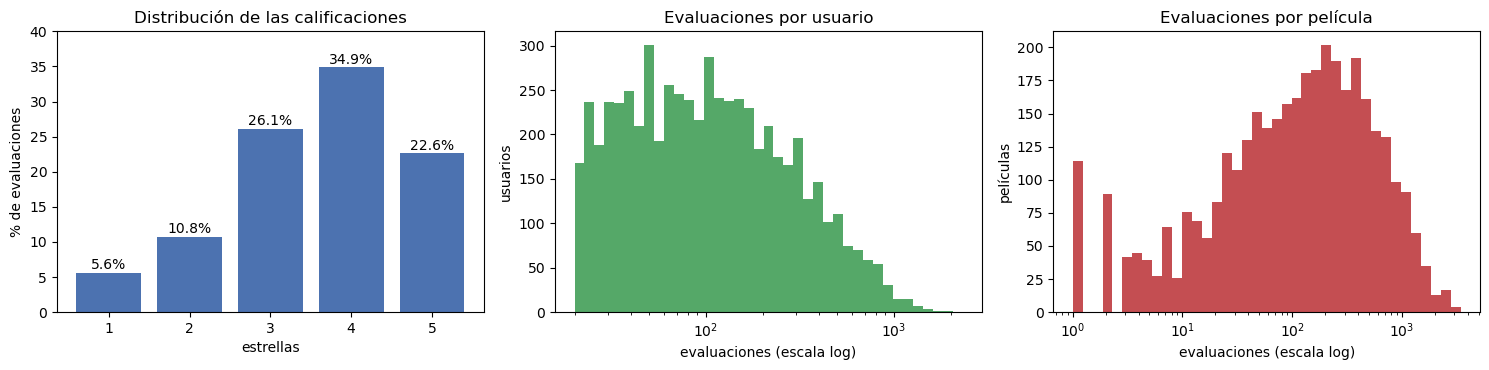

El 10% de las películas más evaluadas concentra el 44.4% de las evaluaciones
Más evaluada: American Beauty (1999) (3,428)


,count,mean,std,min,25%,50%,75%,max
por usuario,6040.0,165.6,192.7,20.0,44.0,96.0,208.0,2314.0
por película,3706.0,269.9,384.0,1.0,33.0,123.5,350.0,3428.0


In [6]:
# Exploración: distribución de calificaciones y actividad por usuario / película
por_usuario = ratings.groupby("UserID").size()
por_pelicula = ratings.groupby("MovieID").size()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].bar(dist.index, dist["%"], color="#4C72B0")
for x, p in zip(dist.index, dist["%"]):
    axes[0].text(x, p + 0.5, f"{p:.1f}%", ha="center")
axes[0].set(title="Distribución de las calificaciones", xlabel="estrellas", ylabel="% de evaluaciones",
            xticks=escala, ylim=(0, 40))
axes[1].hist(por_usuario, bins=np.logspace(np.log10(20), np.log10(por_usuario.max()), 40), color="#55A868")
axes[1].set(xscale="log", title="Evaluaciones por usuario", xlabel="evaluaciones (escala log)", ylabel="usuarios")
axes[2].hist(por_pelicula, bins=np.logspace(0, np.log10(por_pelicula.max()), 40), color="#C44E52")
axes[2].set(xscale="log", title="Evaluaciones por película", xlabel="evaluaciones (escala log)", ylabel="películas")
plt.tight_layout()
plt.show()

orden_pop = por_pelicula.sort_values(ascending=False)
pct_top10 = orden_pop.head(int(0.10 * len(orden_pop))).sum() / n_evaluaciones
print(f"El 10% de las películas más evaluadas concentra el {pct_top10:.1%} de las evaluaciones")
print(f"Más evaluada: {movies.set_index('MovieID').Title[orden_pop.index[0]]} ({orden_pop.iloc[0]:,})")
pd.DataFrame({"por usuario": por_usuario.describe(), "por película": por_pelicula.describe()}).T.round(1)

In [7]:
# Contexto de películas y usuarios (se usará en el sistema híbrido)
generos = movies.Genres.str.split("|").explode().value_counts()
print(f"{len(generos)} géneros | películas con más de un género: {movies.Genres.str.contains('|', regex=False).mean():.1%}")
print(f"Estrenos: {movies.Year.min()}-{movies.Year.max()} | evaluaciones entre "
      f"{ratings.Fecha.min():%Y-%m-%d} y {ratings.Fecha.max():%Y-%m-%d}")
print(f"Género del usuario: {users.Gender.value_counts(normalize=True).round(3).to_dict()} | "
      f"grupos de edad: {sorted(users.Age.unique().tolist())} | ocupaciones: {users.Occupation.nunique()}")
generos.to_frame("películas").T

18 géneros | películas con más de un género: 47.8%
Estrenos: 1919-2000 | evaluaciones entre 2000-04-25 y 2003-02-28
Género del usuario: {'M': 0.717, 'F': 0.283} | grupos de edad: [1, 18, 25, 35, 45, 50, 56] | ocupaciones: 21


Genres,Drama,Comedy,Action,Thriller,Romance,Horror,Adventure,Sci-Fi,Children's,Crime,War,Documentary,Musical,Mystery,Animation,Fantasy,Western,Film-Noir
películas,1603,1200,503,492,471,343,283,276,251,211,143,127,114,106,105,68,68,44


### Ejercicio 1. Respuestas

Los archivos usan `::` como separador y la codificación *latin-1*. Los controles de calidad no encuentran valores nulos, pares (usuario, película) duplicados ni evaluaciones de usuarios o películas que no existan en sus catálogos. Los tres archivos son consistentes entre sí.

**a. Cantidades exactas**

| Concepto | Cantidad |
|---|---|
| Usuarios | **6,040** (todos tienen evaluaciones; cada uno tiene al menos 20) |
| Películas en `movies.dat` | **3,883** |
| Películas con al menos una evaluación | **3,706** (177 nunca fueron evaluadas) |
| Evaluaciones | **1,000,209** |

Las 177 películas sin evaluaciones no aportan nada al filtrado colaborativo, porque no hay usuarios que las conecten con otras. Por eso la matriz de utilidad usa solo las 3,706 películas evaluadas.

**b. Escala de evaluación**

Las películas se califican con **estrellas enteras de 1 a 5**. No hay ceros ni medias estrellas. La distribución está cargada hacia los valores altos:

| Estrellas | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| % de evaluaciones | 5.6 | 10.8 | 26.1 | **34.9** | 22.6 |

La media es **3.58** y la mediana **4**. El 57.5% de las evaluaciones son de 4 o 5 estrellas. Este sesgo positivo es típico: la gente ve (y califica) lo que espera que le guste, así que las calificaciones **no faltan al azar**. En la práctica, un "3" está por debajo del promedio de muchos usuarios. Además, unos usuarios califican con más generosidad que otros. Por eso en el ejercicio 3 se centra cada calificación respecto a la media de su usuario.

La actividad está muy concentrada (gráficas en escala logarítmica). Los usuarios tienen entre 20 y 2,314 evaluaciones (mediana 96). Las películas tienen entre 1 y 3,428 (*American Beauty*), con mediana 123.5. El 10% de las películas más vistas reúne el 44.4% de todas las evaluaciones. Esta "cola larga" explica la dispersión que se mide en el ejercicio 2.

# **Ejercicio - 2: matriz de utilidad**

In [8]:
# Matriz de utilidad R: filas = usuarios (ordenados por UserID), columnas = películas (ordenadas por MovieID)
u_cat = pd.Categorical(ratings.UserID)
m_cat = pd.Categorical(ratings.MovieID)
user_ids = u_cat.categories.to_numpy()      # fila i    ↔ user_ids[i]
movie_ids = m_cat.categories.to_numpy()     # columna j ↔ movie_ids[j]
R = sp.csr_matrix((ratings.Rating.to_numpy(dtype=np.float32), (u_cat.codes, m_cat.codes)),
                  shape=(len(user_ids), len(movie_ids)))
titulos = movies.set_index("MovieID").loc[movie_ids, "Title"].to_numpy()

act_u = np.diff(R.indptr)            # evaluaciones por usuario
pop_m = np.diff(R.tocsc().indptr)    # evaluaciones por película

n_u, n_m = R.shape
celdas = n_u * n_m
densidad = R.nnz / celdas
mem_densa = celdas * 8 / 1024**2
mem_csr = (R.data.nbytes + R.indices.nbytes + R.indptr.nbytes) / 1024**2

resumen_R = pd.Series({
    "Dimensión": f"{n_u:,} usuarios x {n_m:,} películas",
    "Celdas totales": f"{celdas:,}",
    "Celdas con calificación": f"{R.nnz:,}",
    "Densidad": f"{densidad:.4%}",
    "Dispersión (sparsity)": f"{1 - densidad:.4%}",
    "Películas evaluadas por usuario (promedio)": f"{R.nnz / n_u:.1f} de {n_m:,}",
    "Evaluaciones por película (promedio)": f"{R.nnz / n_m:.1f} de {n_u:,}",
    "Memoria como matriz densa (float64)": f"{mem_densa:,.1f} MB",
    "Memoria en formato disperso CSR": f"{mem_csr:,.1f} MB",
}, name="valor")
print(f"Con las {n_peliculas:,} películas del catálogo la dispersión sería {1 - R.nnz / (n_u * n_peliculas):.2%}")
resumen_R.to_frame()

Con las 3,883 películas del catálogo la dispersión sería 95.74%


,valor
Dimensión,"6,040 usuarios x 3,706 películas"
Celdas totales,"22,384,240"
Celdas con calificación,"1,000,209"
Densidad,4.4684%
Dispersión (sparsity),95.5316%
Películas evaluadas por usuario (promedio),"165.6 de 3,706"
Evaluaciones por película (promedio),"269.9 de 6,040"
Memoria como matriz densa (float64),170.8 MB
Memoria en formato disperso CSR,7.7 MB


Title,American Beauty (1999),Star Wars: Episode IV - A New Hope (1977),Star Wars: Episode V - The Empire Strikes Back (1980),Star Wars: Episode VI - Return of the Jedi (1983),Jurassic Park (1993),Saving Private Ryan (1998)
UserID,,,,,,
1,NaN,4.0,NaN,NaN,NaN,5.0
2,4.0,NaN,5.0,4.0,5.0,4.0
3,4.0,5.0,4.0,4.0,4.0,NaN
4,NaN,5.0,2.0,3.0,4.0,5.0
5,4.0,NaN,NaN,NaN,NaN,2.0
6,1.0,NaN,NaN,3.0,NaN,NaN
7,NaN,NaN,5.0,NaN,4.0,5.0
8,5.0,NaN,NaN,4.0,5.0,5.0
9,4.0,NaN,NaN,4.0,4.0,5.0


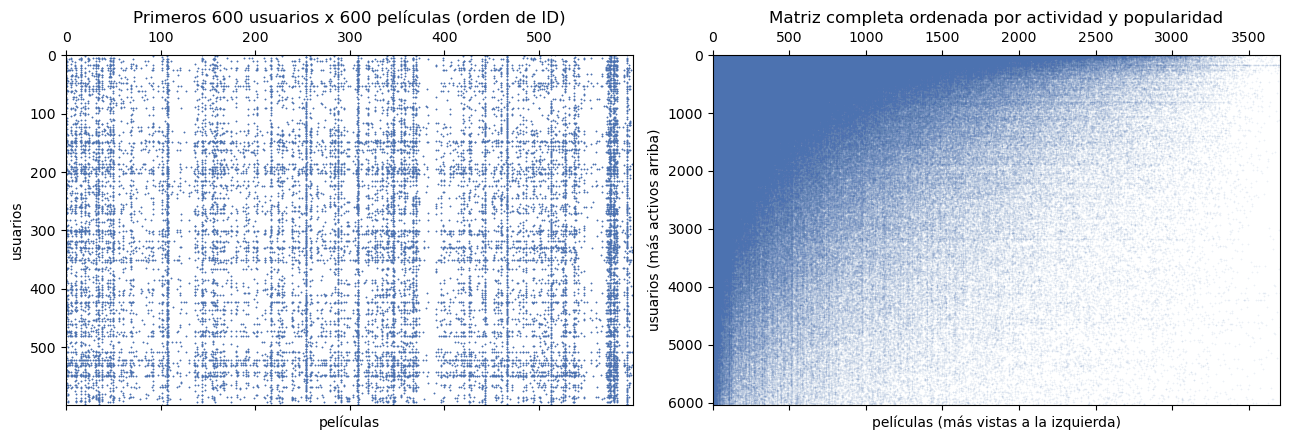

In [9]:
# Vista de una esquina de R (NaN = el usuario no vio/calificó la película)
populares = orden_pop.index[:6]
cols = np.searchsorted(movie_ids, populares)
muestra = pd.DataFrame(R[:10][:, cols].toarray(), index=pd.Index(user_ids[:10], name="UserID"),
                       columns=movies.set_index("MovieID").loc[populares, "Title"])
display(muestra.replace(0, np.nan))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].spy(R[:600, :600], markersize=0.4, aspect="auto", color="#4C72B0")
axes[0].set(title="Primeros 600 usuarios x 600 películas (orden de ID)", xlabel="películas", ylabel="usuarios")
R_ord = R[np.argsort(-act_u)][:, np.argsort(-pop_m)]
axes[1].spy(R_ord, markersize=0.03, aspect="auto", color="#4C72B0")
axes[1].set(title="Matriz completa ordenada por actividad y popularidad", xlabel="películas (más vistas a la izquierda)",
            ylabel="usuarios (más activos arriba)")
plt.tight_layout()
plt.show()

### Ejercicio 2. Matriz de utilidad

**Orden elegido.** $R \in \mathbb{R}^{6040 \times 3706}$, con **usuarios en las filas** (ordenados por `UserID`) y **películas en las columnas** (ordenadas por `MovieID`). La entrada $r_{ui}$ es la calificación del usuario $u$ a la película $i$, y una celda vacía indica que no hay calificación. Es la convención estándar de filtrado colaborativo. Guardamos los vectores `user_ids` y `movie_ids` para traducir posiciones a IDs y títulos. Para obtener los factores latentes **de las películas** (ejercicio 3) factorizamos la transpuesta $R^\top$ (películas x usuarios), de modo que cada fila del resultado sea el vector latente de una película. La matriz se guarda en formato disperso CSR.

**a. Dimensión y dispersión**

| | Valor |
|---|---|
| Dimensión | 6,040 x 3,706 = 22,384,240 celdas |
| Celdas con calificación | 1,000,209 |
| **Densidad** | **4.47%** |
| **Dispersión (sparsity)** | **95.53%** |
| Memoria densa (float64) vs CSR | ≈ 171 MB vs ≈ 7.7 MB |

(Con las 3,883 películas del catálogo, la dispersión sube a 95.74%.)

**b. ¿Qué nos dice la dispersión?**

* **Desconocemos el 95.5% de las preferencias.** En promedio, cada usuario calificó 166 de 3,706 películas (4.5%) y cada película recibió 270 evaluaciones de 6,040 posibles. Recomendar es, en el fondo, **completar la matriz**: estimar las celdas vacías a partir del pequeño porcentaje observado.
* **Una celda vacía no significa "no le gustó".** Significa "no hay información". Si se trata como un 0, se confunde *no vista* con *calificación pésima*, y eso es justo lo que hay que evitar al aplicar SVD.
* **Los datos no faltan al azar.** La matriz ordenada muestra un bloque denso arriba a la izquierda (usuarios activos y películas populares) y una cola larga casi vacía. El 10% de las películas concentra el 44.4% de las evaluaciones. Las películas poco vistas tendrán factores latentes poco confiables y el modelo tenderá a favorecer las populares (sesgo de popularidad).
* **En términos relativos, la matriz es densa.** MovieLens 1M solo incluye usuarios con al menos 20 evaluaciones. En el Netflix Prize, la dispersión era de ≈ 98.8% (100 millones de evaluaciones en 480,189 x 17,770 celdas), y en comercio electrónico suele superar el 99.9%. En producción el problema es todavía más difícil.

**c. Implicaciones computacionales de las matrices muy dispersas**

1. **Almacenamiento.** En formato denso, la matriz ocupa ≈ 171 MB. En CSR solo se guardan los valores observados y sus índices: ≈ 7.7 MB, es decir, 22 veces menos. A la escala de Netflix, la versión densa (8,500 millones de celdas, ≈ 68 GB) ni siquiera cabe en memoria. Hay que elegir el formato según la operación: COO para construir la matriz, CSR para recorrer filas y multiplicar, CSC para recorrer columnas.
2. **Evitar operaciones que densifican.** `.toarray()`, restar una media a *toda* la matriz o centrar columnas como hace `PCA` llenan las celdas vacías y destruyen la dispersión. Por eso se centra **solo sobre las celdas observadas** y se usa `TruncatedSVD`, que no centra y acepta matrices dispersas.
3. **Algoritmos truncados.** La SVD completa cuesta $O(m\,n\,\min(m,n))$. Los métodos truncados (aleatorizados o ARPACK) solo necesitan productos matriz-vector, con costo ≈ $O(\text{nnz}\cdot k)$, y calculan únicamente las $k$ componentes necesarias.
4. **Sesgo de los ceros.** La SVD clásica minimiza el error sobre *todas* las celdas, incluidas las vacías, así que aprende a reproducir los ceros. Las mitigaciones son centrar por usuario (el 0 pasa a significar "en el promedio del usuario") o usar factorizaciones que solo ajustan las celdas observadas (Funk-SVD/SGD, ALS), con regularización.
5. **Similitudes ruidosas.** Dos películas comparten pocos usuarios, así que una similitud calculada sobre pocos datos coincidentes es inestable. Los factores latentes resuelven esto porque comparan películas en un espacio denso de $k$ dimensiones. Aun así, la matriz de similitud entre películas crece como $n^2$ (3,706² ≈ 13.7 millones, manejable). Con millones de artículos se requieren búsquedas aproximadas de vecinos (ANN).
6. **Arranque en frío y evaluación.** Un usuario o una película nuevos tienen una fila o columna vacía, y el modelo colaborativo no puede decir nada sobre ellos. Esto motiva el sistema híbrido del ejercicio 7. Al dividir en entrenamiento y prueba hay que asegurar que cada usuario y película de prueba aparezca en entrenamiento, y el error se mide solo sobre celdas observadas.

# **Ejercicio - 3: varianza explicada y número de componentes latentes**

In [10]:
# Centrado por usuario SOLO en las celdas observadas: las vacías siguen en 0 ("sin información")
media_usuario = np.asarray(R.sum(axis=1)).ravel() / act_u
Rc = R.astype(np.float64)
Rc.data -= np.repeat(media_usuario, act_u)
X_pel = Rc.T.tocsr()      # películas x usuarios: cada fila es una película

print("Matriz que se factoriza:", X_pel.shape,
      f"| máx |media por columna| = {np.abs(np.asarray(X_pel.mean(axis=0))).max():.1e}")

Matriz que se factoriza: (3706, 6040) | máx |media por columna| = 6.8e-16


In [11]:
def espectro_completo(M):
    """Todos los σ² vía los eigenvalores de M·Mᵀ (3706 x 3706). Se densifica UNA vez (≈ 180 MB) solo para
    este diagnóstico del espectro completo; los modelos usan TruncatedSVD sobre la matriz dispersa."""
    D = M.toarray()
    lam = np.linalg.eigvalsh(D @ D.T)[::-1]
    return np.clip(lam, 0, None)


t0 = time.perf_counter()
lam = espectro_completo(X_pel)
# Análisis paralelo: mismas celdas y mismos valores, pero permutados al azar (sin estructura de gustos)
rng = np.random.default_rng(RANDOM_STATE)
X_nulo = X_pel.copy()
X_nulo.data = rng.permutation(X_nulo.data)
lam_nulo = espectro_completo(X_nulo)
print(f"Espectros calculados en {time.perf_counter() - t0:.0f} s")

var_ratio = lam / lam.sum()
var_ratio_nulo = lam_nulo / lam.sum()        # misma norma de Frobenius → mismo denominador
var_acum = np.cumsum(var_ratio)
rango = int((lam > lam[0] * 1e-10).sum())
K_UMBRAL = {p: int(np.searchsorted(var_acum, p) + 1) for p in (0.80, 0.90, 0.95)}
k_senal = int(np.argmax(lam <= lam_nulo))    # componentes que superan al ruido

# Verificación: coincide con explained_variance_ratio_ de TruncatedSVD
for k in (10, 50):
    svd_k = TruncatedSVD(n_components=k, algorithm="arpack", random_state=RANDOM_STATE).fit(X_pel)
    print(f"k = {k:>2}: TruncatedSVD = {svd_k.explained_variance_ratio_.sum():.4%} | "
          f"espectro completo = {var_acum[k - 1]:.4%}")

Espectros calculados en 9 s


k = 10: TruncatedSVD = 13.3657% | espectro completo = 13.3657%


k = 50: TruncatedSVD = 24.1147% | espectro completo = 24.1147%


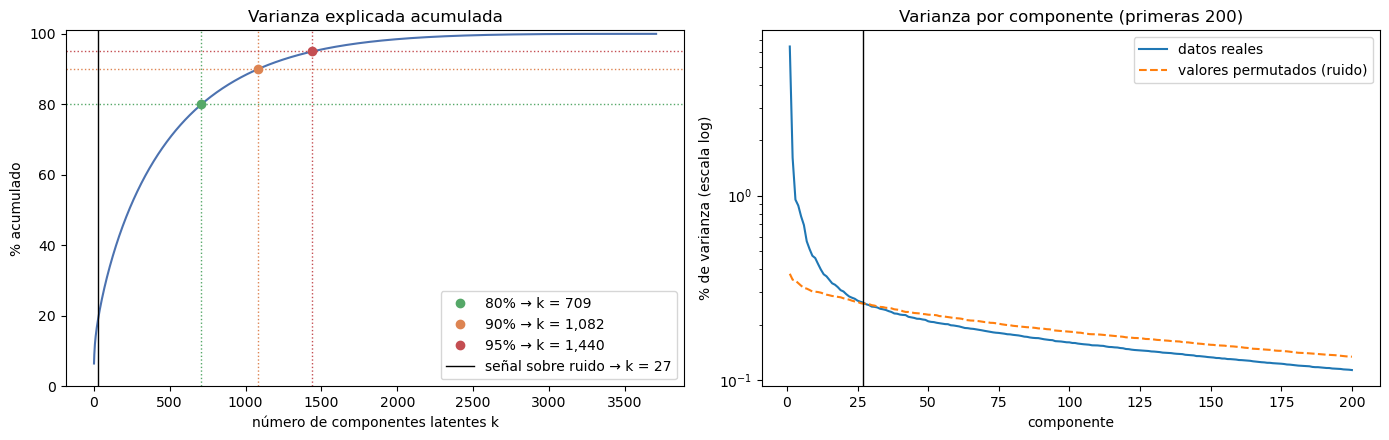

In [12]:
# 3a. Varianza explicada acumulada vs número de componentes
ks = np.arange(1, len(lam) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax = axes[0]
ax.plot(ks, 100 * var_acum, color="#4C72B0")
for (p, k), c in zip(K_UMBRAL.items(), ["#55A868", "#DD8452", "#C44E52"]):
    ax.axhline(100 * p, ls=":", color=c, lw=1)
    ax.axvline(k, ls=":", color=c, lw=1)
    ax.plot(k, 100 * p, "o", color=c, label=f"{p:.0%} → k = {k:,}")
ax.axvline(k_senal, color="black", lw=1, label=f"señal sobre ruido → k = {k_senal}")
ax.set(title="Varianza explicada acumulada", xlabel="número de componentes latentes k",
       ylabel="% acumulado", ylim=(0, 101))
ax.legend(loc="lower right")

ax = axes[1]
m = max(200, int(1.5 * k_senal))
ax.semilogy(ks[:m], 100 * var_ratio[:m], label="datos reales")
ax.semilogy(ks[:m], 100 * var_ratio_nulo[:m], "--", label="valores permutados (ruido)")
ax.axvline(k_senal, color="black", lw=1)
ax.set(title=f"Varianza por componente (primeras {m})", xlabel="componente",
       ylabel="% de varianza (escala log)")
ax.legend()
plt.tight_layout()
plt.show()

In [13]:
# 3b. Componentes necesarias para 80%, 90% y 95%
for p, k in K_UMBRAL.items():
    print(f"Para {p:.0%} de varianza acumulada se necesitan k = {k:,} componentes ({k / rango:.1%} del rango, {rango:,})")
print(f"Componentes por encima del ruido (análisis paralelo): {k_senal} → explican {var_acum[k_senal - 1]:.1%}")

hitos = sorted({h for h in [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, k_senal, rango] if 1 <= h <= rango})
pd.DataFrame({"varianza de la componente k (%)": 100 * var_ratio[np.array(hitos) - 1],
              "varianza acumulada (%)": 100 * var_acum[np.array(hitos) - 1]},
             index=pd.Index(hitos, name="k")).round(3)

Para 80% de varianza acumulada se necesitan k = 709 componentes (19.4% del rango, 3,658)
Para 90% de varianza acumulada se necesitan k = 1,082 componentes (29.6% del rango, 3,658)
Para 95% de varianza acumulada se necesitan k = 1,440 componentes (39.4% del rango, 3,658)
Componentes por encima del ruido (análisis paralelo): 27 → explican 18.8%


,varianza de la componente k (%),varianza acumulada (%)
k,,
1,6.445,6.445
2,1.608,8.054
5,0.773,10.662
10,0.459,13.366
20,0.302,16.872
27,0.263,18.802
50,0.208,24.115
100,0.160,33.169
200,0.113,46.557


In [14]:
# 3c. Factorización con el k seleccionado y lectura de los factores latentes
K_VARIANZA = k_senal      # criterio elegido en 3c
svd_var = TruncatedSVD(n_components=K_VARIANZA, algorithm="arpack", random_state=RANDOM_STATE)
factores_pel = svd_var.fit_transform(X_pel)          # películas x k  (= U·Σ)
print(f"Factores latentes de las películas: {factores_pel.shape} | "
      f"varianza explicada = {svd_var.explained_variance_ratio_.sum():.2%}")

idx = np.where(pop_m >= 100)[0]       # extremos leídos solo con películas con ≥ 100 evaluaciones
for c in range(3):
    orden = idx[np.argsort(factores_pel[idx, c])]
    print(f"\nComponente {c + 1}")
    print("  extremo (+):", " | ".join(titulos[orden[-5:][::-1]]))
    print("  extremo (-):", " | ".join(titulos[orden[:5]]))

Factores latentes de las películas: (3706, 27) | varianza explicada = 18.80%

Componente 1
  extremo (+): Star Wars: Episode IV - A New Hope (1977) | Raiders of the Lost Ark (1981) | Star Wars: Episode V - The Empire Strikes Back (1980) | American Beauty (1999) | Godfather, The (1972)
  extremo (-): Wild Wild West (1999) | Batman & Robin (1997) | Congo (1995) | Judge Dredd (1995) | Howard the Duck (1986)

Componente 2
  extremo (+): Independence Day (ID4) (1996) | Jurassic Park (1993) | Star Wars: Episode VI - Return of the Jedi (1983) | Braveheart (1995) | Forrest Gump (1994)
  extremo (-): Fargo (1996) | Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1963) | Annie Hall (1977) | Citizen Kane (1941) | Chinatown (1974)

Componente 3
  extremo (+): Casablanca (1942) | Wizard of Oz, The (1939) | African Queen, The (1951) | It's a Wonderful Life (1946) | Gone with the Wind (1939)
  extremo (-): American Beauty (1999) | Fight Club (1999) | Being John Malkovich (1999) 

### Ejercicio 3. Varianza explicada y número de componentes latentes

**Preparación.** Antes de factorizar, cada calificación se centra respecto a la media de su usuario, **solo en las celdas observadas**. Así se elimina el sesgo de los usuarios generosos o exigentes, y una celda vacía (0) pasa a significar "en el promedio del usuario" en lugar de "calificación cero". Factorizamos la matriz películas x usuarios (3,706 x 6,040). Como las calificaciones centradas de cada usuario suman cero, **cada columna tiene media exactamente 0** (el máximo observado es 7e-16). Por eso `TruncatedSVD` equivale aquí a un PCA y la varianza explicada de la componente $k$ es $\sigma_k^2 / \sum_j \sigma_j^2$. Para trazar la curva completa calculamos todos los valores singulares una sola vez. La verificación con `TruncatedSVD` da exactamente los mismos porcentajes (13.37% con k = 10 y 24.11% con k = 50). El rango de la matriz es 3,658: hay 114 películas con una sola evaluación, y cuando el mismo usuario es el único que calificó varias de ellas, sus filas son proporcionales.

**a.** Ver la gráfica izquierda.

**b. Componentes necesarias**

| Varianza acumulada | Componentes k | % del rango (3,658) |
|---|---|---|
| 80% | **709** | 19.4% |
| 90% | **1,082** | 29.6% |
| 95% | **1,440** | 39.4% |

Solo la primera componente destaca (6.4%). Después la curva crece lentamente y no tiene un codo claro: 10 componentes explican el 13.4%, 50 el 24.1%, 100 el 33.2% y 500 el 70.5%. A partir de la componente 27, cada una aporta menos de 0.26%, y en la 500 apenas 0.06%. Esto se debe a que el 95.5% de la matriz son ceros y a que las calificaciones tienen ruido: esa variación aleatoria se reparte en *todas* las direcciones, así que alcanzar 80-95% implica modelar sobre todo ruido.

**c. Selección: k = 27**

Para separar la señal del ruido aplicamos un **análisis paralelo** (Horn). Repetimos el cálculo sobre la misma matriz con los valores permutados al azar: mismas celdas, mismas calificaciones, sin estructura de gustos (gráfica derecha). La primera componente real explica 6.4%, contra 0.38% de la primera componente aleatoria. Las curvas se cruzan en la **componente 27**: a partir de ahí, la varianza de cada componente real es igual o menor que la que produciría el puro azar. Elegimos **k = 27**, que explica el **18.8%** de la varianza, por estas razones:

1. **Es información real, no ruido.** Las 27 componentes que conservamos superan a las de la matriz permutada. Las que descartamos no se distinguen del ruido y solo harían que el modelo memorice celdas vacías.
2. **Los umbrales fijos no son adecuados aquí.** Pedir 80%, 90% o 95% exigiría 709, 1,082 o 1,440 componentes, es decir, vectores de hasta el 40% del tamaño de la matriz original. Se perdería el propósito de la reducción de dimensión (comprimir los gustos en pocos factores) y se pagaría más cómputo en las similitudes.
3. **Los factores tienen interpretación clara** (películas con al menos 100 evaluaciones; el signo de cada componente es arbitrario):
   * **Componente 1, calidad percibida:** *Star Wars IV*, *Raiders of the Lost Ark*, *The Empire Strikes Back*, *The Godfather* frente a fracasos como *Batman & Robin*, *Wild Wild West*, *Howard the Duck*, *Judge Dredd*.
   * **Componente 2, taquilla frente a cine de autor:** *Independence Day*, *Jurassic Park*, *Braveheart*, *Forrest Gump* frente a *Fargo*, *Dr. Strangelove*, *Annie Hall*, *Citizen Kane*, *Chinatown*.
   * **Componente 3, clásicos frente a cine de los 90:** *Casablanca*, *The Wizard of Oz*, *It's a Wonderful Life*, *Gone with the Wind* frente a *Fight Club*, *Pulp Fiction*, *Being John Malkovich*, *The Matrix*.

   Ninguno de estos ejes se le dio al modelo: los descubrió solo a partir de las calificaciones.
4. **Advertencia.** La varianza explicada mide qué tan bien se **reconstruye** la matriz observada (incluidos sus ceros), no qué tan bien se **predicen** calificaciones nuevas. Un 18.8% suena bajo, pero el 81% restante es en su mayoría ruido de muestreo. El ejercicio 4 revisa la elección con el RMSE sobre datos de prueba, y el ejercicio 5 compara ambos criterios.

# **Ejercicio - 4: métrica RMSE y número de componentes latentes**



### Protocolo de evaluación

**Partición (inciso a).** Dividimos las 1,000,209 evaluaciones en **80% entrenamiento y 20% prueba**, estratificando por usuario: cada usuario conserva el 80% de sus calificaciones para entrenar y el 20% para evaluar. Como todos tienen al menos 20 evaluaciones, cada uno aporta al menos 16 a entrenamiento, así que el modelo siempre conoce a la persona a la que le va a predecir. Las pocas evaluaciones de prueba cuya película no aparece en entrenamiento reciben la predicción por defecto, que es la media del usuario.

**El conjunto de prueba no se usa para elegir nada.** Para escoger `k` separamos además un 12.5% del entrenamiento (10% del total) como **validación**. Con el 70% restante (*ajuste*) se entrena cada modelo candidato, la validación elige `k`, y la prueba solo reporta el error final del modelo reentrenado con todo el 80%.

**Modelo.** Es el mismo del ejercicio 3: calificaciones centradas por la media del usuario (calculada solo con el entrenamiento), celdas vacías en 0 y SVD truncada de rango $k$. La predicción es

$$\hat r_{ui} = \bar r_u + \sum_{j=1}^{k} u_{uj}\,\sigma_j\,v_{ij}, \qquad \hat r_{ui} \in [1, 5].$$

Por el teorema de Eckart-Young, la SVD truncada de rango $k$ son exactamente las primeras $k$ componentes de la SVD completa. Por eso calculamos la SVD completa una sola vez por conjunto y evaluamos todas las $k$ sumando componentes de forma incremental, en lugar de reentrenar cientos de modelos.

In [15]:
# 4a. Partición 80/20 estratificada por usuario y, dentro del 80%, ajuste/validación (70/10)
evals = pd.DataFrame({"u": u_cat.codes.astype(np.int32),       # fila del usuario en R
                      "m": m_cat.codes.astype(np.int32),       # columna de la película en R
                      "r": ratings.Rating.to_numpy(np.float64)})
train, test = train_test_split(evals, test_size=0.20, stratify=evals.u, random_state=RANDOM_STATE)
ajuste, valid = train_test_split(train, test_size=0.125, stratify=train.u, random_state=RANDOM_STATE)

nuevas = ~test.m.isin(train.m)
print(f"Evaluaciones de prueba cuya película no está en entrenamiento: {nuevas.sum()} "
      f"({test.m[nuevas].nunique()} películas) → se predicen con la media del usuario")
pd.DataFrame({
    "evaluaciones": [len(d) for d in (train, test, ajuste, valid)],
    "% del total": [round(100 * len(d) / len(evals), 1) for d in (train, test, ajuste, valid)],
    "usuarios": [d.u.nunique() for d in (train, test, ajuste, valid)],
    "películas": [d.m.nunique() for d in (train, test, ajuste, valid)],
}, index=["Entrenamiento", "Prueba", "  · ajuste", "  · validación"])

Evaluaciones de prueba cuya película no está en entrenamiento: 32 (27 películas) → se predicen con la media del usuario


,evaluaciones,% del total,usuarios,películas
Entrenamiento,800167,80.0,6040,3679
Prueba,200042,20.0,6040,3476
· ajuste,700146,70.0,6040,3661
· validación,100021,10.0,6040,3325


In [16]:
def matriz_utilidad(d, shape=R.shape):
    """Matriz usuarios x películas (CSR) con las evaluaciones del subconjunto d, en los mismos índices que R."""
    return sp.csr_matrix((d.r.to_numpy(), (d.u.to_numpy(), d.m.to_numpy())), shape=shape)


def svd_completa(R_tr, sesgo_pelicula=False, amortiguador=10.0):
    """Centra por usuario (y, si se pide, resta el sesgo de cada película) solo con datos de entrenamiento y obtiene
    TODAS las componentes de la SVD vía eigh(XᵀX). Devuelve (medias de usuario, sesgos de película, P = UΣ, V)."""
    cnt = np.diff(R_tr.indptr)
    mu_u = np.asarray(R_tr.sum(axis=1)).ravel() / np.maximum(cnt, 1)
    Xc = R_tr.copy()
    Xc.data = Xc.data - np.repeat(mu_u, cnt)
    b_i = np.zeros(R_tr.shape[1])
    if sesgo_pelicula:   # cuánto se aleja cada película de la media de sus usuarios, amortiguado hacia 0
        Xcsc = Xc.tocsc()
        cm = np.diff(Xcsc.indptr)
        b_i = np.asarray(Xcsc.sum(axis=0)).ravel() / (cm + amortiguador)
        Xcsc.data = Xcsc.data - np.repeat(b_i, cm)
        Xc = Xcsc.tocsr()
    D = Xc.toarray()
    _, V = np.linalg.eigh(D.T @ D)
    V = np.ascontiguousarray(V[:, ::-1])      # de mayor a menor valor singular (contigua para que BLAS sea rápido)
    return mu_u, b_i, D @ V, V


def rmse_por_k(modelo, d, ks):
    """RMSE sobre el subconjunto d para cada k de ks (orden creciente), sumando componentes de forma incremental."""
    mu_u, b_i, P, V = modelo
    u, m, y = d.u.to_numpy(), d.m.to_numpy(), d.r.to_numpy()
    base, acum, previo, res = mu_u[u] + b_i[m], np.zeros(len(d)), 0, {}
    for k in ks:
        acum += np.einsum("ij,ij->i", P[u, previo:k], V[m, previo:k])
        previo = k
        res[k] = np.sqrt(np.mean((y - np.clip(base + acum, 1, 5)) ** 2))
    return pd.Series(res)


def errores_cuadraticos(modelo, d, k):
    """Error cuadrático de cada evaluación de d con el modelo de rango k (para el bootstrap del ejercicio 5)."""
    mu_u, b_i, P, V = modelo
    u, m, y = d.u.to_numpy(), d.m.to_numpy(), d.r.to_numpy()
    pred = mu_u[u] + b_i[m] + np.einsum("ij,ij->i", P[u, :k], V[m, :k])
    return (y - np.clip(pred, 1, 5)) ** 2

Curvas calculadas en 84 s
Mínimo en validación: k = 22 (RMSE = 0.9685) | mínimo en prueba (solo como referencia): k = 21 (RMSE = 0.9592)


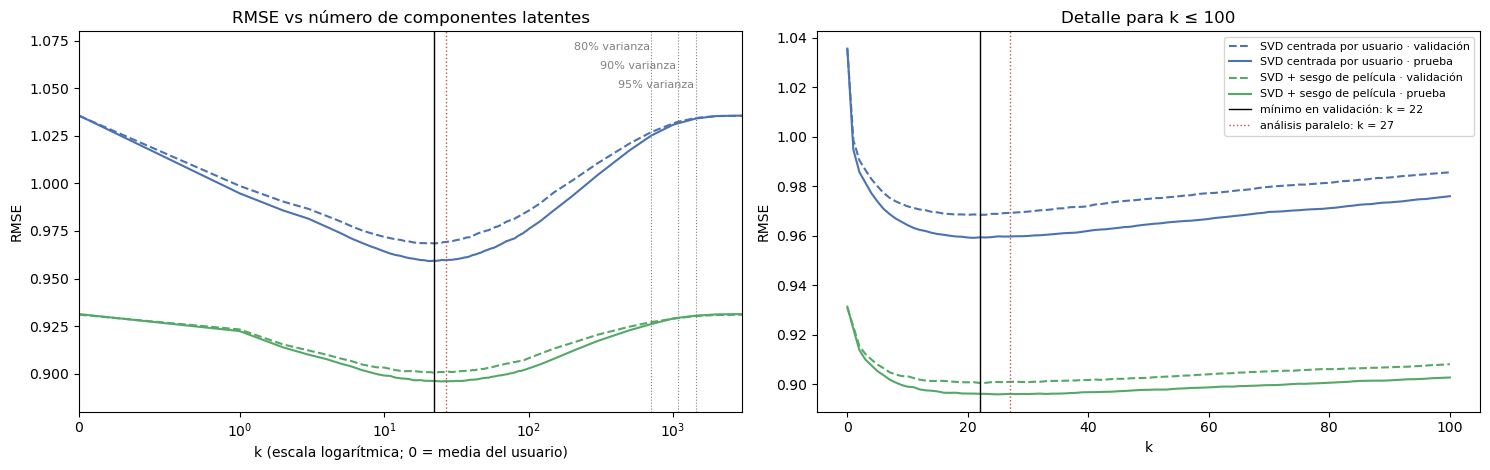

SVD centrada por usuario         SVD + sesgo de película        
                   validación  prueba              validación  prueba
k                                                                    
0                      1.0356  1.0357                  0.9310  0.9313
1                      0.9987  0.9948                  0.9232  0.9223
5                      0.9800  0.9739                  0.9080  0.9053
10                     0.9719  0.9643                  0.9032  0.8990
15                     0.9694  0.9607                  0.9013  0.8971
20                     0.9685  0.9593                  0.9007  0.8962
22                     0.9685  0.9594                  0.9005  0.8961
27                     0.9692  0.9597                  0.9009  0.8961
30                     0.9698  0.9599                  0.9008  0.8960
50                     0.9749  0.9646                  0.9026  0.8977
100                    0.9856  0.9760                  0.9081  0.9027
200                    1.0014  0.9933                  0.9161  0.9118
500                    1.0210  1.0174                  0.9247  0.9228
709                    1.0271  1.0252                  0.9271  0.9261
1082                   1.0324  1.0316                  0.9292  0.9294
1440                   1.0344  1.0341                  0.9303  0.9305
2000                   1.0354  1.0355                  0.9308  0.9311

In [17]:
# 4c. Curvas de RMSE: validación (modelo entrenado con el 70%) y prueba (modelo entrenado con el 80%)
KS = sorted(set(range(0, 101)) | {120, 150, 200, 300, 500, 709, 1000, 1082, 1440, 2000, 3000})
PRINCIPAL, CON_SESGO = "SVD centrada por usuario", "SVD + sesgo de película"
t0 = time.perf_counter()
curvas = {}
for nombre, sesgo in [(PRINCIPAL, False), (CON_SESGO, True)]:
    modelo_ajuste = svd_completa(matriz_utilidad(ajuste), sesgo)
    curvas[(nombre, "validación")] = rmse_por_k(modelo_ajuste, valid, KS)
    if not sesgo:
        modelo_val = modelo_ajuste            # se conserva para el bootstrap del ejercicio 5
    curvas[(nombre, "prueba")] = rmse_por_k(svd_completa(matriz_utilidad(train), sesgo), test, KS)
del modelo_ajuste
curvas = pd.DataFrame(curvas)
curvas.index.name = "k"
print(f"Curvas calculadas en {time.perf_counter() - t0:.0f} s")

K_RMSE = int(curvas[(PRINCIPAL, "validación")].idxmin())
k_test = int(curvas[(PRINCIPAL, "prueba")].idxmin())
print(f"Mínimo en validación: k = {K_RMSE} (RMSE = {curvas[(PRINCIPAL, 'validación')][K_RMSE]:.4f}) | "
      f"mínimo en prueba (solo como referencia): k = {k_test} (RMSE = {curvas[(PRINCIPAL, 'prueba')][k_test]:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, kmax in zip(axes, [None, 100]):
    for (nombre, conjunto), serie in curvas.items():
        s = serie if kmax is None else serie.loc[:kmax]
        ax.plot(s.index, s.values, ls="-" if conjunto == "prueba" else "--", lw=1.5,
                color="#4C72B0" if nombre == PRINCIPAL else "#55A868", label=f"{nombre} · {conjunto}")
    ax.axvline(K_RMSE, color="black", lw=1, label=f"mínimo en validación: k = {K_RMSE}")
    ax.axvline(K_VARIANZA, color="#C44E52", lw=1, ls=":", label=f"análisis paralelo: k = {K_VARIANZA}")
for (p, k), y_txt in zip(K_UMBRAL.items(), [1.070, 1.060, 1.050]):
    axes[0].axvline(k, color="grey", lw=0.8, ls=":")
    axes[0].text(k * 0.97, y_txt, f"{p:.0%} varianza", ha="right", fontsize=8, color="grey")
axes[0].set_xscale("symlog", linthresh=1)
axes[0].set(title="RMSE vs número de componentes latentes", xlabel="k (escala logarítmica; 0 = media del usuario)",
            ylabel="RMSE", ylim=(0.88, 1.08), xlim=(0, 3000))
axes[1].set(title="Detalle para k ≤ 100", xlabel="k", ylabel="RMSE")
axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

hitos_rmse = sorted({0, 1, 5, 10, 15, 20, K_RMSE, K_VARIANZA, 30, 50, 100, 200, 500, 2000, *K_UMBRAL.values()})
curvas.loc[hitos_rmse].round(4)

In [18]:
# 4b. Modelo SVD con TruncatedSVD (k = K_RMSE), entrenado con el 80% y evaluado en el 20% de prueba
R_train = matriz_utilidad(train)
cnt_tr = np.diff(R_train.indptr)
mu_tr = np.asarray(R_train.sum(axis=1)).ravel() / cnt_tr
X_tr = R_train.copy()
X_tr.data -= np.repeat(mu_tr, cnt_tr)

svd_rmse = TruncatedSVD(n_components=K_RMSE, algorithm="arpack", random_state=RANDOM_STATE)
P_tr = svd_rmse.fit_transform(X_tr)         # usuarios x k  (= UΣ)
V_tr = svd_rmse.components_                 # k x películas (= Vᵀ)
u, m, y = test.u.to_numpy(), test.m.to_numpy(), test.r.to_numpy()
pred_svd = np.clip(mu_tr[u] + np.einsum("ij,ji->i", P_tr[u], V_tr[:, m]), 1, 5)

def rmse(y, p): return float(np.sqrt(np.mean((y - p) ** 2)))
def mae(y, p): return float(np.mean(np.abs(y - p)))

media_global = train.r.mean()
modelos_base = {
    "Media global": np.full(len(y), media_global),
    "Media del usuario (k = 0)": np.clip(mu_tr[u], 1, 5),
    f"SVD truncada (k = {K_RMSE})": pred_svd,
}
tabla_rmse = pd.DataFrame({"RMSE": {n: rmse(y, p) for n, p in modelos_base.items()},
                           "MAE": {n: mae(y, p) for n, p in modelos_base.items()}})
tabla_rmse.loc[f"{CON_SESGO} (k = {K_RMSE})", "RMSE"] = curvas[(CON_SESGO, "prueba")][K_RMSE]
tabla_rmse["mejora vs media global (%)"] = 100 * (1 - tabla_rmse.RMSE / tabla_rmse.RMSE.iloc[0])
print(f"Verificación: RMSE con TruncatedSVD = {rmse(y, pred_svd):.4f} | con la SVD completa truncada en k = {K_RMSE}: "
      f"{curvas[(PRINCIPAL, 'prueba')][K_RMSE]:.4f}")
tabla_rmse.round(4)

Verificación: RMSE con TruncatedSVD = 0.9594 | con la SVD completa truncada en k = 22: 0.9594


,RMSE,MAE,mejora vs media global (%)
Media global,1.1166,0.9335,0.0000
Media del usuario (k = 0),1.0357,0.8289,7.2493
SVD truncada (k = 22),0.9594,0.7592,14.0822
SVD + sesgo de película (k = 22),0.8961,NaN,19.7482


### Ejercicio 4. Respuestas

**a. Partición.** 800,167 evaluaciones (80%) para entrenamiento y 200,042 (20%) para prueba. Dentro del entrenamiento, 700,146 son de ajuste y 100,021 de validación. Los 6,040 usuarios están en todos los conjuntos. Solo 32 evaluaciones de prueba (de 27 películas) corresponden a películas sin evaluaciones en entrenamiento; para ellas se predice la media del usuario.

**b. RMSE en prueba.** El modelo SVD con **k = 22** obtiene un **RMSE de 0.9594** (MAE de 0.7592) en las 200,042 evaluaciones de prueba. En promedio, la predicción se equivoca por menos de una estrella. La verificación confirma que `TruncatedSVD` da exactamente el mismo error que la SVD completa truncada en k = 22.

| Modelo | RMSE prueba | Mejora vs media global |
|---|---|---|
| Media global (3.58 para todos) | 1.1166 | – |
| Media de cada usuario (k = 0) | 1.0357 | 7.2% |
| **SVD truncada, k = 22** | **0.9594** | **14.1%** |
| SVD + sesgo de película, k = 22 (variante) | 0.8961 | 19.7% |

Los factores latentes reducen el error un 7.4% respecto a predecir la media de cada usuario. Esa mejora es lo que aporta el filtrado colaborativo.

**c. Curva RMSE vs k.** Tiene forma de **U**:

* **De k = 0 a k ≈ 20, el error baja rápido** (1.0357 → 0.9593 en prueba). Cada componente agrega un patrón de gustos real que generaliza a evaluaciones no vistas.
* **Entre k = 15 y k = 30 la curva es casi plana**: las diferencias son menores de 0.0015.
* **A partir de k ≈ 30 el error sube sin parar** (0.9760 con k = 100 y 1.0174 con k = 500). Con los valores que pedían los umbrales de varianza llega a 1.0252 (k = 709, 80%), 1.0316 (k = 1,082, 90%) y 1.0341 (k = 1,440, 95%).
* **Con k = 2,000 el RMSE es 1.0355, prácticamente el de la media del usuario.** Con casi todas las componentes, la SVD reproduce la matriz de entrenamiento tal cual, incluidos sus ceros. Así que para cada celda no vista vuelve a predecir "0 de desviación", es decir, la media del usuario. Es sobreajuste en estado puro: el modelo memoriza las celdas vacías.

Las curvas de validación y de prueba son paralelas. La de prueba queda un poco más abajo porque ese modelo se entrena con el 80% y no con el 70% de los datos. Por eso la elección hecha en validación se traslada bien a la prueba.

**d. Selección: k = 22.** Es el mínimo del RMSE en validación (0.9685), elegido **sin mirar la prueba**. En prueba da 0.9594, a 0.0002 del mínimo de prueba (k = 21). Como la curva es casi plana entre 15 y 30, cualquier valor de esa zona sería razonable. Elegimos el mínimo de validación porque es el criterio objetivo y además es parsimonioso.

**Variante con sesgo de película.** Si además de la media del usuario se resta el sesgo de cada película (cuánto mejor o peor se califica que el promedio de sus usuarios, amortiguado con 10 pseudoevaluaciones), el RMSE baja a **0.8961**, un 6.6% mejor. El valor óptimo en validación vuelve a ser k = 22. Esto refuerza que el número de factores latentes es una propiedad de los datos y no del preprocesamiento. Para el resto de la actividad conservamos el centrado solo por usuario, por dos razones: mantiene la coherencia con el ejercicio 3, y el sistema de recomendación (ejercicios 6-8) compara películas por similitud, no predice calificaciones. Para esa tarea, el "nivel de calidad" de cada película (la componente 1) es información útil y no conviene eliminarlo.

# **Ejercicio - 5: comparación varianza explicada vs RMSE**

In [19]:
# Bootstrap pareado en validación: ¿es real la diferencia de RMSE entre k = K_RMSE y k = K_VARIANZA?
e_rmse = errores_cuadraticos(modelo_val, valid, K_RMSE)
e_var = errores_cuadraticos(modelo_val, valid, K_VARIANZA)
rng_b = np.random.default_rng(RANDOM_STATE)
n = len(e_rmse)
remuestras = [rng_b.integers(0, n, n) for _ in range(1000)]
dif = np.array([np.sqrt(e_var[i].mean()) - np.sqrt(e_rmse[i].mean()) for i in remuestras])
ee_rmse = np.std([np.sqrt(e_rmse[i].mean()) for i in remuestras])
print(f"RMSE validación: k = {K_RMSE} → {np.sqrt(e_rmse.mean()):.4f} | k = {K_VARIANZA} → {np.sqrt(e_var.mean()):.4f}")
print(f"Diferencia (k = {K_VARIANZA} menos k = {K_RMSE}) = {dif.mean():+.4f} | IC 95%: [{np.percentile(dif, 2.5):+.4f}, "
      f"{np.percentile(dif, 97.5):+.4f}] | error estándar del RMSE: {ee_rmse:.4f}")

criterios = {
    "Media del usuario (sin factores)": 0,
    "Mínimo RMSE en validación": K_RMSE,
    "Análisis paralelo (varianza sobre ruido)": K_VARIANZA,
    "80% de varianza": K_UMBRAL[0.80],
    "90% de varianza": K_UMBRAL[0.90],
    "95% de varianza": K_UMBRAL[0.95],
}
pd.DataFrame({
    "k": criterios,
    "varianza explicada (%)": {c: 100 * var_acum[k - 1] if k else 0.0 for c, k in criterios.items()},
    "RMSE validación": {c: curvas[(PRINCIPAL, "validación")][k] for c, k in criterios.items()},
    "RMSE prueba": {c: curvas[(PRINCIPAL, "prueba")][k] for c, k in criterios.items()},
}).round(4)

RMSE validación: k = 22 → 0.9685 | k = 27 → 0.9692
Diferencia (k = 27 menos k = 22) = +0.0008 | IC 95%: [+0.0004, +0.0012] | error estándar del RMSE: 0.0022


,k,varianza explicada (%),RMSE validación,RMSE prueba
Media del usuario (sin factores),0,0.0000,1.0356,1.0357
Mínimo RMSE en validación,22,17.4481,0.9685,0.9594
Análisis paralelo (varianza sobre ruido),27,18.8024,0.9692,0.9597
80% de varianza,709,80.0076,1.0271,1.0252
90% de varianza,1082,90.0052,1.0324,1.0316
95% de varianza,1440,95.0014,1.0344,1.0341


### Ejercicio 5. Comparación de criterios y valor final

| Criterio | k | Varianza explicada | RMSE validación | RMSE prueba |
|---|---|---|---|---|
| Sin factores (media del usuario) | 0 | 0% | 1.0356 | 1.0357 |
| **Mínimo RMSE en validación** | **22** | 17.4% | **0.9685** | **0.9594** |
| Análisis paralelo | 27 | 18.8% | 0.9692 | 0.9597 |
| 80% de varianza | 709 | 80.0% | 1.0271 | 1.0252 |
| 90% de varianza | 1,082 | 90.0% | 1.0324 | 1.0316 |
| 95% de varianza | 1,440 | 95.0% | 1.0344 | 1.0341 |

**Los dos criterios miden cosas distintas.** La varianza explicada mide cuánto de la matriz observada, **incluidos sus ceros**, se puede reconstruir. El RMSE mide qué tan bien se **predicen calificaciones que el modelo no vio**, que es lo que importa al recomendar. Los umbrales clásicos (80-95%) llevan a un **sobreajuste severo**: con 709 a 1,440 componentes el error es casi el de no usar factores, porque esas componentes reconstruyen ruido y celdas vacías. Un 90% de varianza "suena" mejor que un 17%, pero predice peor.

**Donde los criterios sí coinciden es en el análisis de señal sobre ruido.** El análisis paralelo (k = 27) y el mínimo del RMSE (k = 22) caen en la misma zona, y llegamos a ellos por dos caminos independientes: uno no supervisado (¿qué componentes superan al ruido?) y uno supervisado (¿cuáles mejoran la predicción?). Para saber si la diferencia entre ambos es real, hicimos un bootstrap pareado con 1,000 remuestreos de las 100,021 evaluaciones de validación. El RMSE con k = 27 es mayor por +0.0008, con intervalo de confianza del 95% de [+0.0004, +0.0012]. **El intervalo excluye el cero**: k = 22 es consistentemente mejor. Pero la magnitud es mínima (0.08% del error), y equivale a un tercio del error estándar del propio RMSE (0.0022). En la práctica, ambos valores predicen igual de bien, y k = 22 lo hace con 5 componentes menos.

**Valor seleccionado: k = 22.**

1. Es el que mejor generaliza según un conjunto de validación independiente de la prueba, con una ventaja pequeña pero estadísticamente consistente sobre k = 27.
2. Está dentro de la señal detectada por el análisis paralelo: las 22 componentes superan al ruido. Las 5 adicionales hasta k = 27 son señal débil que no mejora la predicción.
3. Es el más parsimonioso de los dos. Con vectores más cortos, la similitud se calcula más rápido y es menos ruidosa.

En resumen, **el análisis paralelo marca el límite superior de componentes con información, y el RMSE elige dentro de ese límite el valor que mejor predice.** Este valor (`K_FINAL = 22`) se usa en el resto de la actividad.

# **Ejercicio - 6: sistema de recomendación colaborativo**

In [20]:
# 6a-b. Factores latentes de las películas con el k final (todas las evaluaciones) y matriz de similitud del coseno
K_FINAL = K_RMSE
svd_final = TruncatedSVD(n_components=K_FINAL, algorithm="arpack", random_state=RANDOM_STATE)
factores = svd_final.fit_transform(X_pel)          # 3706 x K_FINAL: vector latente de cada película (UΣ)
S_svd = cosine_similarity(factores)

print(f"Factores latentes: {factores.shape} | varianza explicada: {svd_final.explained_variance_ratio_.sum():.1%}")
print(f"Matriz de similitud: {S_svd.shape} = {S_svd.size:,} valores | simétrica: {np.allclose(S_svd, S_svd.T)} | "
      f"diagonal = {S_svd.diagonal().min():.3f} | rango [{S_svd.min():.3f}, {S_svd.max():.3f}]")

# Ficha de cada película (misma posición que en R) y diccionarios de búsqueda
info = movies.set_index("MovieID").loc[movie_ids].reset_index()
info["n_eval"] = pop_m
info["calif_media"] = np.asarray(R.sum(axis=0)).ravel() / pop_m
pos = {t: i for i, t in enumerate(titulos)}            # título   → posición
pos_id = {int(mid): i for i, mid in enumerate(movie_ids)}  # MovieID → posición


def recomendar(S, semillas, n=10):
    """Top-n por similitud promedio con las películas semilla (títulos o posiciones), excluyéndolas."""
    semillas = [pos[t] if isinstance(t, str) else int(t) for t in np.atleast_1d(semillas)]
    s = S[semillas].mean(axis=0)
    s[semillas] = -np.inf
    orden = np.argsort(-s)[:n]
    return pd.DataFrame({"Título": titulos[orden], "Géneros": info.Genres.values[orden],
                         "Evaluaciones": pop_m[orden], "Calif. media": info.calif_media.values[orden].round(2),
                         "Similitud": s[orden].round(3)}, index=pd.RangeIndex(1, n + 1, name="#"))


pd.DataFrame(S_svd[:5, :5], index=titulos[:5], columns=titulos[:5]).round(3)

Factores latentes: (3706, 22) | varianza explicada: 17.4%


Matriz de similitud: (3706, 3706) = 13,734,436 valores | simétrica: True | diagonal = 1.000 | rango [-1.000, 1.000]


,Toy Story (1995),Jumanji (1995),Grumpier Old Men (1995),Waiting to Exhale (1995),Father of the Bride Part II (1995)
Toy Story (1995),1.000,-0.247,-0.233,-0.253,-0.278
Jumanji (1995),-0.247,1.000,0.482,0.478,0.486
Grumpier Old Men (1995),-0.233,0.482,1.000,0.745,0.748
Waiting to Exhale (1995),-0.253,0.478,0.745,1.000,0.817
Father of the Bride Part II (1995),-0.278,0.486,0.748,0.817,1.000


In [21]:
# 6c. Película elegida y sus 10 recomendaciones por SVD
PELICULA = "Matrix, The (1999)"
display(info.loc[[pos[PELICULA]], ["MovieID", "Title", "Genres", "Year", "n_eval", "calif_media"]].round(2))
rec_svd = recomendar(S_svd, PELICULA)
rec_svd

,MovieID,Title,Genres,Year,n_eval,calif_media
2374,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,1999,2590,4.32


,Título,Géneros,Evaluaciones,Calif. media,Similitud
#,,,,,
1,Terminator 2: Judgment Day (1991),Action|Sci-Fi|Thriller,2649,4.06,0.803
2,"Terminator, The (1984)",Action|Sci-Fi|Thriller,2098,4.15,0.739
3,Gladiator (2000),Action|Drama,1924,4.11,0.738
4,"Professional, The (a.k.a. Leon: The Professional) (1994)",Crime|Drama|Romance|Thriller,923,4.11,0.723
5,Aliens (1986),Action|Sci-Fi|Thriller|War,1820,4.13,0.721
6,Twelve Monkeys (1995),Drama|Sci-Fi,1511,3.95,0.707
7,X-Men (2000),Action|Sci-Fi,1511,3.82,0.706
8,Better Living Through Circuitry (1999),Documentary,16,3.81,0.704
9,"Sixth Sense, The (1999)",Thriller,2459,4.41,0.695


### Ejercicio 6. Sistema de recomendación colaborativo (SVD, k = 22)

**a. Matriz de similitud.** Cada película queda representada por su vector de 22 factores latentes, una fila de $U\Sigma$ en la factorización películas x usuarios. La similitud entre dos películas es el coseno del ángulo entre sus vectores: 1 si apuntan en la misma dirección (gustan y disgustan a la misma gente), 0 si no tienen relación y −1 si son opuestas.

**b. Dimensión: 3,706 x 3,706** (13.7 millones de valores), una fila y una columna por cada película con evaluaciones. Es simétrica, su diagonal vale 1 y sus valores están en [−1, 1]. Ocupa ≈ 110 MB, cantidad manejable aquí. Con millones de películas no se calcularía completa: se buscarían los vecinos más cercanos de forma aproximada.

**c. Película elegida: *The Matrix* (1999)** (Action | Sci-Fi | Thriller), con 2,590 evaluaciones y calificación media de 4.32. Sus 10 recomendaciones están en la tabla anterior, de *Terminator 2* (0.803) a *Blade Runner* (0.681).

**d. ¿Son coherentes?** Sí, en general mucho:

* **El modelo nunca vio los géneros y aun así los "descubre".** 9 de las 10 recomendaciones comparten al menos un género con *The Matrix*, y 6 son de ciencia ficción. Los primeros lugares (*Terminator 2*, *The Terminator*, *Aliens*) son justo las películas de acción y ciencia ficción que un experto pondría junto a *The Matrix*.
* **También captura afinidades que van más allá del género.** *Gladiator*, *Léon: The Professional* o *The Sixth Sense* no son de ciencia ficción, pero son películas de finales de los 90, con tono oscuro y muy populares entre el mismo público. Eso es justo lo que aporta el filtrado colaborativo: "a quien le gustó A también le gustó B".
* **Hay una recomendación débil:** *Better Living Through Circuitry* (1999), un documental con solo **16 evaluaciones**. Con tan pocos datos, su vector latente depende de unas cuantas personas que, al parecer, también son fans de *The Matrix*. Como el coseno ignora cuántos datos respaldan cada vector, una película poco vista puede quedar muy arriba. Es la principal debilidad del método puro y se corrige con un umbral mínimo de evaluaciones o, como veremos, con la información de contenido del modelo híbrido.

**e. Explicación para alguien no técnico.** Imagina que cada película tiene una "huella de gustos": no qué es la película, sino **a quién le gusta y a quién no**. El método SVD revisa el millón de calificaciones y descubre por sí solo unos 22 "ejes de gusto" escondidos. Por ejemplo: ¿es un clásico aclamado o un fracaso?, ¿es un éxito de taquilla o cine de autor?, ¿es cine clásico o de los 90? Nadie le dice al sistema qué significan esos ejes. Los encuentra porque los mismos grupos de personas tienden a calificar alto o bajo los mismos tipos de películas. Después, cada película se ubica con una puntuación en cada eje, como coordenadas en un mapa. Recomendar es buscar **las películas más cercanas en ese mapa**. Si viste *The Matrix*, el sistema te sugiere las que ocupan el mismo "vecindario" de gustos, como *Terminator 2*, aunque no sepa nada de robots ni de ciencia ficción.

# **Ejercicio - 7: sistema de recomendación híbrido**

In [22]:
# 7a. Año de lanzamiento → década (variable categórica en one-hot)
info["Decada"] = info.Year.astype(int) // 10 * 10
B_decada = pd.get_dummies(info.Decada.astype(str) + "s", dtype=float)
info.Decada.value_counts().sort_index().rename(lambda d: f"{d}s").to_frame("películas").T

Decada,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s
películas,3,23,72,120,165,187,240,592,2152,152


In [23]:
# 7b. Género (multi-etiqueta) y perfil de la audiencia a partir de users.dat (género y edad de quienes evaluaron)
B_genero = info.Genres.str.get_dummies("|").astype(float)

ru = ratings[["UserID", "MovieID"]].merge(users[["UserID", "Gender", "Age"]], on="UserID")
ru["Mujer"] = (ru.Gender == "F").astype(float)
ru["Edad"] = pd.cut(ru.Age, bins=[0, 24, 44, 99], labels=["Joven (<25)", "Adulto (25-44)", "Maduro (45+)"])
conteos_dem = pd.concat([ru.groupby("MovieID").Mujer.sum(), pd.crosstab(ru.MovieID, ru.Edad)], axis=1).loc[movie_ids]
global_dem = pd.Series({"Mujer": ru.Mujer.mean(), **ru.Edad.value_counts(normalize=True)})

M_PREVIO = 20   # suavizado bayesiano: con pocas evaluaciones la proporción se acerca a la global
proporciones = (conteos_dem + M_PREVIO * global_dem[conteos_dem.columns]).div(pop_m + M_PREVIO, axis=0)
B_demografia = (proporciones - proporciones.mean()) / proporciones.std()

print("Grupos de edad originales de users.dat (código: usuarios):", users.Age.value_counts().sort_index().to_dict())
print(f"Proporciones globales en las evaluaciones: {global_dem.round(3).to_dict()}")
extremos = [proporciones.Mujer.idxmax(), proporciones["Joven (<25)"].idxmax(), proporciones["Maduro (45+)"].idxmax()]
display(proporciones.loc[[movie_ids[pos[PELICULA]], *extremos]].rename(index=lambda mid: titulos[pos_id[mid]]).round(3))
proporciones.describe().round(3)

Grupos de edad originales de users.dat (código: usuarios): {1: 222, 18: 1103, 25: 2096, 35: 1193, 45: 550, 50: 496, 56: 380}
Proporciones globales en las evaluaciones: {'Mujer': 0.246, 'Adulto (25-44)': 0.594, 'Joven (<25)': 0.211, 'Maduro (45+)': 0.195}


,Mujer,Joven (<25),Adulto (25-44),Maduro (45+)
MovieID,,,,
"Matrix, The (1999)",0.199,0.257,0.589,0.154
Moonlight and Valentino (1995),0.637,0.264,0.593,0.143
Blank Check (1994),0.292,0.545,0.413,0.042
"Pawnbroker, The (1965)",0.221,0.041,0.249,0.710


,Mujer,Joven (<25),Adulto (25-44),Maduro (45+)
count,3706.000,3706.000,3706.000,3706.000
mean,0.255,0.206,0.585,0.209
std,0.088,0.087,0.072,0.095
min,0.062,0.029,0.249,0.023
25%,0.195,0.141,0.543,0.145
50%,0.241,0.200,0.586,0.187
75%,0.304,0.258,0.630,0.254
max,0.637,0.545,0.833,0.710


In [24]:
# 7c. Matriz híbrida: bloques normalizados (norma 1 por fila) y ponderados por √peso
PESOS = {"SVD": 0.55, "Género": 0.25, "Década": 0.10, "Demografía": 0.10}
bloques = {"SVD": factores, "Género": B_genero.to_numpy(), "Década": B_decada.to_numpy(),
           "Demografía": B_demografia.to_numpy()}
H = np.hstack([np.sqrt(PESOS[b]) * normalize(bloques[b]) for b in PESOS])
S_hib = H @ H.T                      # filas de norma 1 → producto punto = coseno = Σ peso_b · coseno_b

display(pd.DataFrame({"columnas": {b: bloques[b].shape[1] for b in PESOS}, "peso": PESOS}).T)
print(f"Matriz híbrida H: {H.shape} | normas de fila: [{np.linalg.norm(H, axis=1).min():.3f}, "
      f"{np.linalg.norm(H, axis=1).max():.3f}] | similitud híbrida: {S_hib.shape}")

# Comprobación: la similitud híbrida es el promedio ponderado de las similitudes de cada bloque
i = pos[PELICULA]
combinada = sum(PESOS[b] * cosine_similarity(bloques[b][[i]], bloques[b])[0] for b in PESOS)
print(f"S_hib = Σ peso · coseno por bloque: {np.allclose(S_hib[i], combinada)}")

,SVD,Género,Década,Demografía
columnas,22.00,18.00,10.0,4.0
peso,0.55,0.25,0.1,0.1


Matriz híbrida H: (3706, 54) | normas de fila: [1.000, 1.000] | similitud híbrida: (3706, 3706)
S_hib = Σ peso · coseno por bloque: True


In [25]:
# 7e. Tabla comparativa SVD vs híbrido para la misma película
rec_hib = recomendar(S_hib, PELICULA)
comparativa = pd.concat({"SVD": rec_svd[["Título", "Similitud"]], "Híbrido": rec_hib[["Título", "Similitud"]]}, axis=1)
en_ambas = set(rec_svd.Título) & set(rec_hib.Título)
print(f"Películas en ambas listas: {len(en_ambas)} → {sorted(en_ambas)}")
display(comparativa)


def desglose(semilla, recs):
    """Aporte de cada bloque (peso · coseno) a la similitud híbrida de cada recomendación."""
    i = pos[semilla]
    filas = {t: {b: PESOS[b] * cosine_similarity(bloques[b][[i]], bloques[b][[pos[t]]])[0, 0] for b in PESOS}
             for t in recs.Título}
    d = pd.DataFrame(filas).T
    d["Total"] = d.sum(axis=1)
    return d.round(3)


desglose(PELICULA, rec_hib)

Películas en ambas listas: 4 → ['Sixth Sense, The (1999)', 'Terminator 2: Judgment Day (1991)', 'Terminator, The (1984)', 'X-Men (2000)']


SVD            \
                                                      Título Similitud   
#                                                                        
1                          Terminator 2: Judgment Day (1991)     0.803   
2                                     Terminator, The (1984)     0.739   
3                                           Gladiator (2000)     0.738   
4   Professional, The (a.k.a. Leon: The Professional) (1994)     0.723   
5                                              Aliens (1986)     0.721   
6                                      Twelve Monkeys (1995)     0.707   
7                                               X-Men (2000)     0.706   
8                     Better Living Through Circuitry (1999)     0.704   
9                                    Sixth Sense, The (1999)     0.695   
10                                       Blade Runner (1982)     0.681   

                              Híbrido            
                               Título Similitud  
#                                                
1   Terminator 2: Judgment Day (1991)     0.878  
2                Fugitive, The (1993)     0.741  
3              Terminator, The (1984)     0.725  
4                 Total Recall (1990)     0.702  
5                    Dark City (1998)     0.696  
6           Fifth Element, The (1997)     0.694  
7                        X-Men (2000)     0.690  
8             Sixth Sense, The (1999)     0.689  
9                      Gattaca (1997)     0.683  
10   Hunt for Red October, The (1990)     0.682

,SVD,Género,Década,Demografía,Total
Terminator 2: Judgment Day (1991),0.442,0.250,0.1,0.087,0.878
"Fugitive, The (1993)",0.348,0.204,0.1,0.089,0.741
"Terminator, The (1984)",0.407,0.250,0.0,0.069,0.725
Total Recall (1990),0.317,0.217,0.1,0.069,0.702
Dark City (1998),0.334,0.167,0.1,0.095,0.696
"Fifth Element, The (1997)",0.294,0.204,0.1,0.096,0.694
X-Men (2000),0.389,0.204,0.0,0.097,0.690
"Sixth Sense, The (1999)",0.382,0.144,0.1,0.062,0.689
Gattaca (1997),0.331,0.167,0.1,0.085,0.683
"Hunt for Red October, The (1990)",0.321,0.204,0.1,0.056,0.682


### Ejercicio 7. Sistema de recomendación híbrido

**a. Década.** El año de estreno (1919-2000) se convierte en década: 1910s, 1920s, …, 2000s, 10 categorías en codificación *one-hot*. El año exacto no sirve directamente en una similitud del coseno, porque un número solo no tiene "dirección". Además, la diferencia entre 1994 y 1996 es irrelevante, mientras que la época (cine de los 50 frente a cine de los 90) sí marca un estilo de producción y un público. La mayoría de las películas son de los 90 (2,152 de 3,706), seguidas de los 80 (592). Las décadas de 1910 y 1920 tienen muy pocas (3 y 23).

**b. Factores elegidos y transformaciones**

| Factor | Fuente | Transformación | Por qué |
|---|---|---|---|
| Década | `movies.dat` | Año → década, *one-hot* (10 columnas) | Época y estilo de producción. |
| Género | `movies.dat` | Multi-etiqueta → 18 columnas binarias | Es el descriptor de contenido más directo. El 47.8% de las películas tiene varios géneros, así que se conservan todos. |
| Género del público | `users.dat` (`Gender`) | % de mujeres entre quienes la evaluaron | Distingue películas con públicos muy distintos. En promedio, el 25.5% del público de una película son mujeres, con un rango de 6% a 64% (*Moonlight and Valentino*). |
| Edad del público | `users.dat` (`Age`) | Los 7 códigos de edad se agrupan en 3 etapas (joven < 25, adulto 25-44, maduro 45+), y se usa el % de cada una | Igual que con la década, se agrupan rangos cuya distinción fina aporta poco. Por ejemplo, 45-49 y 50-55 se comportan parecido. Además, los grupos extremos son pequeños (222 usuarios menores de 18). Los contrastes son claros: *Blank Check* tiene 55% de público joven y *The Pawnbroker* 71% de público maduro. |

Los factores de `users.dat` describen a **personas**, no a películas. Para usarlos como características de una película los **agregamos sobre su audiencia**: qué proporción de quienes la evaluaron son mujeres, jóvenes, adultos o mayores. En películas con pocas evaluaciones esas proporciones son poco confiables (con 3 evaluaciones, un 67% de mujeres no significa nada). Por eso aplicamos un **suavizado bayesiano** con 20 pseudoevaluaciones de la proporción global. Al final, las cuatro proporciones se estandarizan (puntuación z), para que el coseno compare cuánto se *aleja* cada película del público típico y no la proporción bruta, que sería casi igual en todas. Descartamos la ocupación (21 categorías, muchas con pocos usuarios) y el código postal, que añadirían ruido y dimensiones sin una relación clara con el tipo de película.

**c. Matriz híbrida.** Cada bloque se normaliza a norma 1 por fila y se multiplica por la raíz de su peso. Así, el coseno de la matriz completa es exactamente el **promedio ponderado de las similitudes de cada bloque**, lo que la celda comprueba numéricamente. Los pesos no dependen del número de columnas de cada bloque. Su dimensión es **3,706 x 54**: 22 factores SVD + 18 géneros + 10 décadas + 4 demográficos. Los pesos son 55% SVD, 25% género, 10% década y 10% demografía. La señal colaborativa sigue siendo la principal (demostró su valor predictivo en el ejercicio 4), y el contenido la complementa sin dominarla.

**d. Beneficios de la matriz aumentada**

1. **Robustez con pocos datos.** El género y la década no dependen del número de evaluaciones. Una película poco vista ya no puede subir solo por el ruido de su vector latente, como pasaba con el documental de 16 evaluaciones.
2. **Arranque en frío.** Una película nueva, sin evaluaciones, no tiene vector SVD, pero sí tiene género y año. Con el bloque de contenido se le pueden encontrar vecinas desde el primer día.
3. **Coherencia temática.** Las recomendaciones respetan más el género y la época que el usuario espera.
4. **Explicabilidad.** Cada similitud se descompone en "se parecen por gustos, por género, por época y por público" (tabla de desglose), lo que permite justificar las recomendaciones. Esto se aprovecha en el agente del ejercicio 8.
5. **Control de negocio.** Los pesos son perillas explícitas para ajustar el balance entre descubrimiento (más SVD) y afinidad temática (más contenido).

El costo es que el sistema se vuelve más "conservador": puede perder sorpresas valiosas que solo el filtrado colaborativo detecta, y los pesos son una decisión de diseño que habría que validar con usuarios reales (pruebas A/B).

**e.** Ver la tabla comparativa y el desglose por bloques.

**f. Comentarios.** Las dos listas comparten 4 de 10 películas (*Terminator 2*, *The Terminator*, *X-Men* y *The Sixth Sense*), y *Terminator 2* sigue en primer lugar en ambas, ahora con 0.878. Las diferencias son instructivas:

* **El híbrido elimina el documental de 16 evaluaciones** y las películas que solo comparten público pero no contenido (*Gladiator*, *Léon*). En su lugar entran películas de acción y ciencia ficción de los 90 como *Total Recall*, *Dark City*, *The Fifth Element* y *Gattaca*, temáticamente más cercanas a *The Matrix* (realidades simuladas, distopías).
* **El híbrido favorece la misma década.** Clásicos de los 80 como *Aliens* y *Blade Runner* salen de la lista, y entran *The Fugitive* y *The Hunt for Red October* (thrillers de acción de los 90), que tienen menos afinidad de gustos pero coinciden en género y época. El desglose lo muestra: *The Terminator* (1984) y *X-Men* (2000) aportan 0 en el bloque de década, mientras que las películas de los 90 suman 0.10. Es el lado negativo de este bloque: trata 1989 y 1990 como épocas distintas.
* **En el SVD las similitudes son más bajas y están más concentradas** (0.68-0.80). En el híbrido, el bloque de contenido amplía la separación entre la primera recomendación y el resto.

En conjunto, el SVD es mejor para **descubrir** afinidades inesperadas entre públicos, y el híbrido para dar recomendaciones **temáticamente coherentes y robustas**. Las dos fuentes son complementarias, y por eso el agente del ejercicio 8 trabaja con ambas.

# **Ejercicio - 8: sistema de recomendación mediante un agente inteligente**

In [26]:
# 8a. Las 5 películas favoritas del usuario y las 10 recomendaciones de cada sistema
FAVORITAS = ["Batman Returns (1992)", "Mask, The (1994)", "Back to the Future (1985)",
             "Pulp Fiction (1994)", "Aladdin (1992)"]
assert all(t in pos for t in FAVORITAS), [t for t in FAVORITAS if t not in pos]
display(info.loc[[pos[t] for t in FAVORITAS], ["MovieID", "Title", "Genres", "Year", "n_eval", "calif_media"]].round(2))

rec8_svd, rec8_hib = recomendar(S_svd, FAVORITAS), recomendar(S_hib, FAVORITAS)
print(f"En ambas listas: {sorted(set(rec8_svd.Título) & set(rec8_hib.Título))}")
pd.concat({"SVD": rec8_svd[["Título", "Géneros", "Similitud"]],
           "Híbrido": rec8_hib[["Título", "Géneros", "Similitud"]]}, axis=1)

,MovieID,Title,Genres,Year,n_eval,calif_media
1278,1377,Batman Returns (1992),Action|Adventure|Comedy|Crime,1992,1031,2.98
357,367,"Mask, The (1994)",Comedy|Crime|Fantasy,1994,1179,3.28
1178,1270,Back to the Future (1985),Comedy|Sci-Fi,1985,2583,3.99
287,296,Pulp Fiction (1994),Crime|Drama,1994,2171,4.28
574,588,Aladdin (1992),Animation|Children's|Comedy|Musical,1992,1351,3.79


En ambas listas: ["Bug's Life, A (1998)", 'Toy Story (1995)', 'True Lies (1994)']


SVD                                   \
                             Título                          Géneros   
#                                                                      
1   Who Framed Roger Rabbit? (1988)    Adventure|Animation|Film-Noir   
2             Lion King, The (1994)     Animation|Children's|Musical   
3                  True Lies (1994)  Action|Adventure|Comedy|Romance   
4                     Batman (1989)     Action|Adventure|Crime|Drama   
5              Bug's Life, A (1998)      Animation|Children's|Comedy   
6               Ghostbusters (1984)                    Comedy|Horror   
7                        Big (1988)                   Comedy|Fantasy   
8                Beetlejuice (1988)                   Comedy|Fantasy   
9                       Antz (1998)             Animation|Children's   
10                 Toy Story (1995)      Animation|Children's|Comedy   

                             Híbrido                                   \
   Similitud                  Título                          Géneros   
#                                                                       
1      0.361    Wayne's World (1992)                           Comedy   
2      0.297    Bug's Life, A (1998)      Animation|Children's|Comedy   
3      0.297        True Lies (1994)  Action|Adventure|Comedy|Romance   
4      0.295        Liar Liar (1997)                           Comedy   
5      0.292        Toy Story (1995)      Animation|Children's|Comedy   
6      0.289     Men in Black (1997)   Action|Adventure|Comedy|Sci-Fi   
7      0.288      Toy Story 2 (1999)      Animation|Children's|Comedy   
8      0.285  My Cousin Vinny (1992)                           Comedy   
9      0.283    Dumb & Dumber (1994)                           Comedy   
10     0.277    Pleasantville (1998)                           Comedy   

              
   Similitud  
#             
1      0.419  
2      0.417  
3      0.412  
4      0.405  
5      0.405  
6      0.393  
7      0.393  
8      0.386  
9      0.385  
10     0.382

**Similitud con un perfil de 5 películas.** Para cada película candidata se promedia su similitud del coseno con cada una de las 5 favoritas, y se excluyen las propias favoritas. Promediar similitudes, en lugar de comparar contra el vector promedio, evita que un gusto muy marcado domine el perfil: una candidata necesita parecerse *en promedio* a todo el conjunto. Por eso los valores son más bajos que con una sola película (≈ 0.28-0.42). Con favoritas tan variadas (thriller criminal, comedia, animación, superhéroes, ciencia ficción) ninguna película se parece mucho a todas a la vez.

### Diseño del agente (incisos b, c y d)

**Modelo LLM utilizado:** OpenAI, el modelo indicado en `MODELO_LLM` (por defecto `gpt-4.1-mini`), mediante la API de *Chat Completions* con llamadas a funciones (*function calling*). La celda imprime el identificador exacto que devuelve la API. La clave se lee de la variable de entorno `OPENAI_API_KEY` y nunca se escribe en el notebook.

El agente no es una sola llamada al LLM. Es un **ciclo de razonamiento y acción** con herramientas y un validador:

1. **Herramientas.** El LLM no recibe las listas en el mensaje, sino que debe *consultarlas*: `recomendaciones_svd`, `recomendaciones_hibrido` y `ficha_pelicula(movie_id)` (año, géneros, número de evaluaciones, calificación media, público y similitud con el perfil). Todas las cifras que usa provienen de los modelos de los ejercicios 6 y 7.
2. **Decisión.** Con esa evidencia elige 5 películas siguiendo criterios explícitos: afinidad, coincidencia entre ambos sistemas, confiabilidad (al menos 50 evaluaciones), diversidad y calidad. Justifica cada una conectándola con las favoritas concretas del usuario.
3. **Validador (barrera contra alucinaciones).** El código revisa la respuesta: que sea JSON válido, que tenga exactamente 5 películas distintas, que cada `movie_id` exista y esté entre las candidatas, que no sea una favorita, que el título coincida con el catálogo, que la "fuente" declarada (SVD, híbrido o ambas) sea la real y que los años mencionados correspondan a películas del caso. Si algo falla, le devuelve los errores al LLM para que corrija (hasta 2 reintentos).

Así el LLM aporta lo que hace bien (combinar criterios y redactar explicaciones personalizadas) y el sistema conserva el control sobre *qué* se puede recomendar.

In [27]:
# 8b. Configuración del LLM (OpenAI). La clave se lee de la variable de entorno OPENAI_API_KEY.
MODELO_LLM = os.getenv("OPENAI_MODEL", "gpt-4.1-mini")
try:
    from openai import OpenAI
    cliente = OpenAI() if os.getenv("OPENAI_API_KEY") else None
except ImportError:
    cliente = None
# Los modelos de razonamiento (o-series, gpt-5) no aceptan temperatura distinta de la de omisión
PARAMS_LLM = {} if MODELO_LLM.startswith(("o1", "o3", "o4", "gpt-5")) else {"temperature": 0.2, "seed": RANDOM_STATE}
print(f"Modelo configurado: {MODELO_LLM} | parámetros: {PARAMS_LLM} | "
      f"{'cliente listo' if cliente else 'SIN CLAVE: define OPENAI_API_KEY para ejecutar el agente'}")

Modelo configurado: gpt-4.1-mini | parámetros: {'temperature': 0.2, 'seed': 42} | SIN CLAVE: define OPENAI_API_KEY para ejecutar el agente


In [28]:
# 8b-d. Prompt del sistema, herramientas y agente
PROMPT_SISTEMA = """Eres un agente experto en cine que trabaja para una plataforma de streaming. Tu tarea es elegir las 5 mejores películas para un usuario a partir de dos sistemas de recomendación entrenados con MovieLens 1M (1 millón de calificaciones de 6,040 usuarios, películas hasta el año 2000):

- Sistema SVD (filtrado colaborativo): similitud según los patrones de calificación de los usuarios ("a quien le gustaron sus favoritas también le gustó esta").
- Sistema híbrido: combina los factores SVD (55%) con género (25%), década (10%) y perfil demográfico del público (10%).

Herramientas disponibles:
- recomendaciones_svd: las 10 candidatas del sistema SVD con su similitud con el perfil del usuario.
- recomendaciones_hibrido: las 10 candidatas del sistema híbrido con su similitud con el perfil del usuario.
- ficha_pelicula(movie_id): año, géneros, número de evaluaciones, calificación media (1-5), público y similitudes de una película.

Procedimiento obligatorio:
1. Consulta SIEMPRE las dos listas de candidatas.
2. Consulta la ficha de las candidatas que consideres para la selección final.
3. Elige exactamente 5 películas distintas, SOLO entre las candidatas de las dos listas, sin incluir ninguna de las favoritas del usuario.
4. Criterios de selección, en este orden:
   a) Afinidad con los gustos del usuario (géneros, tono y época de sus favoritas).
   b) Preferir películas que aparecen en ambas listas o con similitud alta.
   c) Desconfiar de películas con menos de 50 evaluaciones: su similitud es poco confiable.
   d) Diversidad: que las 5 no sean todas del mismo tipo; cubre los distintos gustos del perfil.
   e) Calidad: a igualdad de condiciones, mayor calificación media.
5. Justifica cada película en 2 o 3 oraciones en español, dirigidas al usuario, conectándola con al menos una de sus favoritas por nombre.
6. Usa SOLO los datos de las herramientas para cifras y hechos verificables (años, géneros, evaluaciones, calificaciones, similitudes). Puedes describir el tono o la temática general de una película muy conocida, pero NO inventes actores, directores, premios ni datos que no estén en las herramientas.

Al terminar responde ÚNICAMENTE con un objeto JSON (sin texto adicional) con esta estructura:
{"perfil_usuario": "<2 oraciones que describen los gustos del usuario>",
 "recomendaciones": [{"movie_id": <entero>, "titulo": "<título exacto como aparece en las herramientas>",
                      "fuente": "<SVD | Híbrido | Ambas>", "justificacion": "<2-3 oraciones>"}]}"""

HERRAMIENTAS = [
    {"type": "function", "function": {
        "name": "recomendaciones_svd",
        "description": "Devuelve las 10 películas candidatas del sistema SVD colaborativo con su similitud con el perfil.",
        "parameters": {"type": "object", "properties": {}, "required": []}}},
    {"type": "function", "function": {
        "name": "recomendaciones_hibrido",
        "description": "Devuelve las 10 películas candidatas del sistema híbrido (SVD + género + década + demografía).",
        "parameters": {"type": "object", "properties": {}, "required": []}}},
    {"type": "function", "function": {
        "name": "ficha_pelicula",
        "description": "Ficha de una película del catálogo: año, géneros, evaluaciones, calificación media, público y similitudes.",
        "parameters": {"type": "object", "properties": {
            "movie_id": {"type": "integer", "description": "MovieID de MovieLens"}}, "required": ["movie_id"]}}},
]


def extraer_json(texto):
    """Toma el primer objeto JSON del texto (tolera bloques ```json ... ```)."""
    inicio, fin = texto.find("{"), texto.rfind("}")
    return json.loads(texto[inicio:fin + 1])


class AgenteRecomendador:
    def __init__(self, favoritas, n_candidatos=10, max_reintentos=2, max_pasos=15):
        self.favoritas = list(favoritas)
        self.fav = [pos[t] for t in favoritas]
        self.max_reintentos, self.max_pasos = max_reintentos, max_pasos
        self.svd = recomendar(S_svd, favoritas, n_candidatos)
        self.hib = recomendar(S_hib, favoritas, n_candidatos)
        self.en_svd, self.en_hib = {pos[t] for t in self.svd.Título}, {pos[t] for t in self.hib.Título}
        self.candidatos = self.en_svd | self.en_hib
        self.sim_svd, self.sim_hib = S_svd[self.fav].mean(axis=0), S_hib[self.fav].mean(axis=0)
        self.traza, self.errores, self.tokens, self.reintentos = [], [], 0, 0
        self.modelo_usado, self.salida, self.segundos = None, None, 0.0

    # ---------- herramientas ----------
    def _lista(self, tabla):
        return [{"movie_id": int(movie_ids[pos[t]]), "titulo": t, "similitud": float(s)}
                for t, s in zip(tabla.Título, tabla.Similitud)]

    def fuente_real(self, i):
        return "Ambas" if i in self.en_svd and i in self.en_hib else ("SVD" if i in self.en_svd else "Híbrido")

    def ficha(self, movie_id):
        i = pos_id.get(int(movie_id))
        if i is None:
            return {"error": f"movie_id {movie_id} no existe en el catálogo"}
        p = proporciones.iloc[i]
        return {"movie_id": int(movie_id), "titulo": titulos[i], "anio": int(info.Year[i]),
                "generos": info.Genres[i].split("|"), "evaluaciones": int(pop_m[i]),
                "calificacion_media": round(float(info.calif_media[i]), 2),
                "publico": {"pct_mujeres": round(100 * float(p["Mujer"]), 1),
                            "grupo_de_edad_mas_representado": p.drop("Mujer").idxmax()},
                "similitud_svd_con_perfil": round(float(self.sim_svd[i]), 3),
                "similitud_hibrida_con_perfil": round(float(self.sim_hib[i]), 3),
                "es_candidata": i in self.candidatos,
                "aparece_en": self.fuente_real(i) if i in self.candidatos else "ninguna lista"}

    def herramienta(self, nombre, args):
        if nombre == "recomendaciones_svd":
            return self._lista(self.svd)
        if nombre == "recomendaciones_hibrido":
            return self._lista(self.hib)
        if nombre == "ficha_pelicula":
            return self.ficha(args.get("movie_id", -1))
        return {"error": f"herramienta desconocida: {nombre}"}

    # ---------- prompt del usuario y validación ----------
    def prompt_usuario(self):
        lineas = "\n".join(f"- {titulos[i]} (movie_id {int(movie_ids[i])}; {info.Genres[i].replace('|', ', ')})"
                           for i in self.fav)
        return f"Mis 5 películas favoritas son:\n{lineas}\n\nRecomiéndame 5 películas y explícame por qué me gustarían."

    def validar(self, salida):
        errores, recs = [], salida.get("recomendaciones", [])
        if len(recs) != 5:
            errores.append(f"Debe haber exactamente 5 recomendaciones y hay {len(recs)}.")
        ids = [r.get("movie_id") for r in recs]
        if len(set(ids)) != len(ids):
            errores.append("Hay películas repetidas.")
        anios_validos = {int(info.Year[j]) for j in self.candidatos | set(self.fav)}
        for r in recs:
            mid, titulo = r.get("movie_id"), r.get("titulo", "")
            i = pos_id.get(mid) if isinstance(mid, int) else None
            if i is None:
                errores.append(f"'{titulo}': el movie_id {mid} no existe en el catálogo.")
                continue
            if i in self.fav:
                errores.append(f"'{titulo}' es una de las favoritas del usuario.")
            elif i not in self.candidatos:
                errores.append(f"'{titulo}' (movie_id {mid}) no está en ninguna de las dos listas de candidatas.")
            else:
                if r.get("fuente") != self.fuente_real(i):
                    errores.append(f"'{titulos[i]}': la fuente es '{self.fuente_real(i)}', no '{r.get('fuente')}'.")
            if titulo != titulos[i]:
                errores.append(f"El movie_id {mid} corresponde a '{titulos[i]}', no a '{titulo}'.")
            anios = {int(a) for a in re.findall(r"\b(19\d{2}|20\d{2})\b", r.get("justificacion", ""))}
            if anios - anios_validos:
                errores.append(f"'{titulos[i]}': la justificación menciona año(s) {sorted(anios - anios_validos)} "
                               "que no corresponden a ninguna película del caso.")
        return errores

    # ---------- ciclo del agente ----------
    def ejecutar(self, verbose=True):
        t0 = time.perf_counter()
        mensajes = [{"role": "system", "content": PROMPT_SISTEMA}, {"role": "user", "content": self.prompt_usuario()}]
        for _ in range(self.max_pasos):
            resp = cliente.chat.completions.create(model=MODELO_LLM, messages=mensajes, tools=HERRAMIENTAS, **PARAMS_LLM)
            self.modelo_usado = resp.model
            self.tokens += resp.usage.total_tokens if resp.usage else 0
            msg = resp.choices[0].message
            if msg.tool_calls:                                   # el LLM decide consultar herramientas
                mensajes.append({"role": "assistant", "content": msg.content or "", "tool_calls": [
                    {"id": tc.id, "type": "function",
                     "function": {"name": tc.function.name, "arguments": tc.function.arguments}}
                    for tc in msg.tool_calls]})
                for tc in msg.tool_calls:
                    args = json.loads(tc.function.arguments or "{}")
                    resultado = self.herramienta(tc.function.name, args)
                    self.traza.append(f"{tc.function.name}({args.get('movie_id', '')})")
                    mensajes.append({"role": "tool", "tool_call_id": tc.id,
                                     "content": json.dumps(resultado, ensure_ascii=False)})
                continue
            mensajes.append({"role": "assistant", "content": msg.content or ""})
            try:                                                 # respuesta final: se valida
                salida = extraer_json(msg.content or "")
                errores = self.validar(salida)
            except (ValueError, AttributeError) as e:
                salida, errores = None, [f"La respuesta no es un JSON válido ({e})."]
            if not errores:
                self.salida = salida
                break
            self.errores.append(errores)
            if verbose:
                print("Validador → errores detectados:", *errores, sep="\n  - ")
            if self.reintentos >= self.max_reintentos:
                break
            self.reintentos += 1
            mensajes.append({"role": "user", "content": "Tu respuesta tiene estos problemas:\n- " + "\n- ".join(errores)
                             + "\nCorrígela respetando todas las reglas y responde solo con el JSON."})
        self.segundos = time.perf_counter() - t0
        self.mensajes = mensajes
        return self.salida

    def tabla(self):
        if not self.salida:
            return pd.DataFrame()
        filas = []
        for k, r in enumerate(self.salida["recomendaciones"], 1):
            i = pos_id[r["movie_id"]]
            filas.append({"#": k, "Título": titulos[i], "Géneros": info.Genres[i], "Fuente": self.fuente_real(i),
                          "Sim. SVD": round(float(self.sim_svd[i]), 3), "Sim. híbrida": round(float(self.sim_hib[i]), 3),
                          "Evaluaciones": int(pop_m[i]), "Calif. media": round(float(info.calif_media[i]), 2),
                          "Justificación del agente": r["justificacion"]})
        return pd.DataFrame(filas).set_index("#")

In [29]:
# 8b-c. Ejecución del agente con las favoritas del usuario
agente = AgenteRecomendador(FAVORITAS)
if cliente is None:
    print("Agente no ejecutado: falta la variable de entorno OPENAI_API_KEY.")
else:
    agente.ejecutar()
    print(f"Modelo: {agente.modelo_usado} | llamadas a herramientas: {len(agente.traza)} → {', '.join(agente.traza)}")
    print(f"Tokens: {agente.tokens:,} | reintentos por el validador: {agente.reintentos} | tiempo: {agente.segundos:.1f} s")
    if agente.salida:
        display(Markdown(f"**Perfil detectado por el agente:** {agente.salida['perfil_usuario']}"))
        with pd.option_context("display.max_colwidth", None):
            display(agente.tabla())

Agente no ejecutado: falta la variable de entorno OPENAI_API_KEY.


In [30]:
# 8d. Prompt completo: mensaje de sistema, mensaje del usuario y definición de herramientas
print("=" * 30, "MENSAJE DE SISTEMA", "=" * 30)
print(PROMPT_SISTEMA)
print("\n" + "=" * 30, "MENSAJE DEL USUARIO", "=" * 30)
print(agente.prompt_usuario())
print("\n" + "=" * 30, "HERRAMIENTAS (function calling)", "=" * 30)
print(json.dumps(HERRAMIENTAS, ensure_ascii=False, indent=2))
print("\n" + "=" * 30, "MENSAJE DE CORRECCIÓN (solo si el validador detecta errores)", "=" * 30)
print("Tu respuesta tiene estos problemas:\n- <errores detectados>\nCorrígela respetando todas las reglas y responde solo con el JSON.")

============================== MENSAJE DE SISTEMA ==============================
Eres un agente experto en cine que trabaja para una plataforma de streaming. Tu tarea es elegir las 5 mejores películas para un usuario a partir de dos sistemas de recomendación entrenados con MovieLens 1M (1 millón de calificaciones de 6,040 usuarios, películas hasta el año 2000):

- Sistema SVD (filtrado colaborativo): similitud según los patrones de calificación de los usuarios ("a quien le gustaron sus favoritas también le gustó esta").
- Sistema híbrido: combina los factores SVD (55%) con género (25%), década (10%) y perfil demográfico del público (10%).

Herramientas disponibles:
- recomendaciones_svd: las 10 candidatas del sistema SVD con su similitud con el perfil del usuario.
- recomendaciones_hibrido: las 10 candidatas del sistema híbrido con su similitud con el perfil del usuario.
- ficha_pelicula(movie_id): año, géneros, número de evaluaciones, calificación media (1-5), público y similitudes de

### Ejercicio 8. Resultados del agente

> **Pendiente de ejecutar con la clave de OpenAI.** Este texto se completa con las salidas reales del agente.

# **Ejercicio - 9: Evaluación del agente**

In [31]:
# 9. Evaluación del agente con perfiles de características distintas
PERFILES = {
    "Darío: comedia, aventura y culto de los 90": FAVORITAS,
    "Clásicos de culto": ["Casablanca (1942)", "Godfather, The (1972)", "Citizen Kane (1941)",
                          "Vertigo (1958)", "Chinatown (1974)"],
    "Familiar / animación": ["Toy Story (1995)", "Lion King, The (1994)", "Beauty and the Beast (1991)",
                             "Babe (1995)", "Little Mermaid, The (1989)"],
    "Terror y ciencia ficción": ["Alien (1979)", "Shining, The (1980)", "Thing, The (1982)",
                                 "Blade Runner (1982)", "Exorcist, The (1973)"],
}
assert all(t in pos for fav in PERFILES.values() for t in fav)

agentes = {}
for nombre, fav in PERFILES.items():
    if cliente is None:
        break
    a = agente if fav == FAVORITAS and agente.salida else AgenteRecomendador(fav)
    if a.salida is None:
        print(f"→ {nombre}")
        a.ejecutar()
    agentes[nombre] = a


def generos_de(indices):
    return set().union(*(info.Genres[i].split("|") for i in indices))


def resumen_agente(a):
    elegidas = [pos_id[r["movie_id"]] for r in a.salida["recomendaciones"]] if a.salida else []
    g_fav = generos_de(a.fav)
    fuentes = pd.Series([a.fuente_real(i) for i in elegidas]).value_counts()
    return {
        "válida": a.salida is not None,
        "errores detectados": sum(len(e) for e in a.errores),
        "reintentos": a.reintentos,
        "comparten género con favoritas": f"{sum(bool(generos_de([i]) & g_fav) for i in elegidas)}/5",
        "géneros distintos": len(generos_de(elegidas)),
        "en ambas listas": int(fuentes.get("Ambas", 0)),
        "solo SVD": int(fuentes.get("SVD", 0)),
        "solo híbrido": int(fuentes.get("Híbrido", 0)),
        "calif. media elegidas": round(float(np.mean(info.calif_media.values[elegidas])), 2) if elegidas else np.nan,
        "calif. media candidatas": round(float(np.mean(info.calif_media.values[list(a.candidatos)])), 2),
        "mín. evaluaciones": int(pop_m[elegidas].min()) if elegidas else np.nan,
        "llamadas a herramientas": len(a.traza),
        "tokens": a.tokens,
        "segundos": round(a.segundos, 1),
    }


if agentes:
    resumen = pd.DataFrame({n: resumen_agente(a) for n, a in agentes.items()})
    display(resumen)
    for nombre, a in agentes.items():
        display(Markdown(f"#### {nombre}\n*Favoritas:* {'; '.join(a.favoritas)}\n\n"
                         f"*Perfil según el agente:* {a.salida['perfil_usuario'] if a.salida else '—'}"))
        with pd.option_context("display.max_colwidth", None):
            display(a.tabla())
else:
    print("Evaluación no ejecutada: falta la variable de entorno OPENAI_API_KEY.")

Evaluación no ejecutada: falta la variable de entorno OPENAI_API_KEY.


In [32]:
# 9d. Costo computacional medido de cada método (por consulta de un perfil de 5 películas)
def cronometrar(f, repeticiones=20):
    t0 = time.perf_counter()
    for _ in range(repeticiones):
        f()
    return 1000 * (time.perf_counter() - t0) / repeticiones

t_svd = cronometrar(lambda: recomendar(S_svd, FAVORITAS))
t_hib = cronometrar(lambda: recomendar(S_hib, FAVORITAS))
t_agente = np.mean([a.segundos for a in agentes.values()]) * 1000 if agentes else np.nan
tokens_agente = np.mean([a.tokens for a in agentes.values()]) if agentes else np.nan
pd.DataFrame({"tiempo por consulta (ms)": [t_svd, t_hib, t_agente],
              "tokens LLM por consulta": [0, 0, tokens_agente]},
             index=["SVD colaborativo", "Híbrido", "Agente LLM"]).round(1)

,tiempo por consulta (ms),tokens LLM por consulta
SVD colaborativo,0.6,0.0
Híbrido,0.6,0.0
Agente LLM,NaN,NaN


### Ejercicio 9. Evaluación del agente

> **Incisos a, b y c pendientes de ejecutar con la clave de OpenAI.** Se completan con el resumen y las tablas de los cuatro perfiles: Darío, clásicos de culto, familiar/animación y terror/ciencia ficción. El análisis revisará la coherencia de cada lista, los errores que detecte el validador y la revisión manual de las justificaciones (hechos no verificables, como actores o directores).

**d. Comparación de los tres métodos**

| Criterio | SVD colaborativo | Híbrido (SVD + contenido) | Agente LLM |
|---|---|---|---|
| **Personalización** | Media. Captura afinidades reales entre públicos, pero responde igual a todos los que tienen las mismas favoritas y no explica nada. | Media-alta. Agrega coherencia de género, época y público, con pesos ajustables. | **Alta.** Interpreta el perfil completo (por ejemplo, "le gustan la comedia y lo oscuro"), equilibra diversidad y calidad y habla en el lenguaje del usuario. |
| **Interpretabilidad** | **Baja.** Los 22 factores son abstractos. Solo algunos se pueden nombrar (calidad, taquilla vs autor, clásico vs moderno). | Media. La similitud se descompone por bloque (gustos, género, década, público). | Alta en apariencia: da razones en lenguaje natural. Pero son explicaciones *post hoc* que pueden sonar convincentes sin ser la causa real de la elección. |
| **Mantenimiento** | Bajo. Reentrenar la SVD periódicamente toma segundos y no requiere decisiones de diseño. | Medio. Además del SVD hay que mantener los catálogos de metadatos y revisar los pesos. | **Alto.** Depende de un proveedor externo (versiones de modelo que cambian, precios, límites de uso), de un prompt que hay que versionar y probar, y de un validador. |
| **Costo computacional** | **Muy bajo.** Una consulta toma menos de 1 ms con la similitud precalculada, sin costo variable. | Muy bajo (menos de 1 ms). La matriz se precalcula igual que la del SVD. | **Alto.** Segundos y miles de tokens por consulta (ver tabla de tiempos), con costo por llamada y latencia de red. Miles de veces más lento que los otros dos. |
| **Riesgo de alucinaciones** | **Nulo.** Solo puede devolver películas que existen en el catálogo, aunque sí puede dar recomendaciones *ruidosas* (el documental de 16 evaluaciones). | Nulo. Además es más robusto ante películas poco vistas. | **Real.** Puede inventar películas, títulos, años o datos (actores, premios). En este diseño, el validador elimina el riesgo de recomendar algo inexistente o fuera de las candidatas. Los hechos dentro del texto libre no se pueden verificar del todo de forma automática. |

# **Ejercicio - 10: Reporte ejecutivo**

**Para:** Dirección General
**De:** Darío Martín Romero Cruz, equipo de Ciencia de Datos
**Asunto:** Sistema de recomendación de películas, resultados y propuesta para producción

**Resumen.** Construimos y evaluamos tres versiones de un sistema de recomendación con 1 millón de calificaciones reales de 6,040 usuarios sobre 3,706 películas (MovieLens). **Recomiendo poner en producción el sistema híbrido como motor de recomendación, y usar el agente con LLM solo como una capa opcional de presentación**, que redacte explicaciones personalizadas a partir de lo que el motor ya decidió, con controles automáticos.

**Qué hicimos y qué encontramos**

1. **Los datos son muy escasos.** Cada usuario ha calificado en promedio el 4.5% del catálogo, y el 10% de las películas concentra el 44% de las calificaciones. El reto es predecir el 95.5% restante.
2. **Motor colaborativo (SVD).** Descubre automáticamente 22 "ejes de gusto" a partir de las calificaciones. Predice la calificación que un usuario daría a una película no vista con un error promedio (RMSE) de 0.96 estrellas, un 14% menos que una predicción ingenua. Validamos el número de ejes con dos métodos independientes: más ejes no mejoran, empeoran. Sus recomendaciones son coherentes: para *The Matrix* sugiere *Terminator 2*, *Aliens* y *Blade Runner* sin conocer los géneros. Su punto débil son las películas con pocas calificaciones.
3. **Motor híbrido.** Combina esos ejes de gusto (55%) con género (25%), época (10%) y tipo de público (10%). Elimina las recomendaciones ruidosas de películas poco vistas, da listas temáticamente más coherentes, puede recomendar títulos nuevos sin historial y permite explicar cada recomendación. Además, sus pesos son palancas de negocio ajustables.
4. **Agente con LLM (OpenAI).** Toma las listas de ambos motores, elige 5 títulos y los justifica en lenguaje natural para cada usuario. La experiencia es claramente superior. Sin embargo, es miles de veces más lento (segundos frente a menos de un milisegundo), tiene un costo por consulta y puede "alucinar". Por eso le pusimos un validador automático que impide recomendar algo fuera del catálogo o de las candidatas.

**Recomendación**

| Componente | Decisión | Por qué |
|---|---|---|
| Motor híbrido | **Producción, para el 100% del tráfico** | Costo casi nulo (milisegundos), sin riesgo de alucinación, robusto, explicable y ajustable. |
| Motor SVD puro | Componente interno del híbrido | Aporta la señal de gustos más valiosa, pero solo no es suficientemente robusto. |
| Agente LLM | **Piloto acotado** (correo semanal, sección "Elegidas para ti", soporte) | Gran valor en la experiencia, pero su costo, latencia y riesgo no justifican usarlo en cada pantalla. |

**Próximos pasos**

1. Prueba A/B del híbrido frente al sistema actual, midiendo clics, horas vistas y retención, durante 4 semanas.
2. Piloto del agente en un canal de bajo volumen. Medir satisfacción y costo por usuario, y auditar una muestra de las justificaciones.
3. Reentrenamiento semanal automático y monitoreo de la calidad (RMSE y cobertura del catálogo).
4. Gobierno del LLM: versionar el prompt, fijar la versión del modelo y tener una alternativa sin LLM si el proveedor falla.

**Riesgos.** Los datos son de 2000-2003 y de un solo sitio, así que los resultados deben confirmarse con datos propios. El sistema tiende a favorecer títulos populares, por lo que conviene vigilar la diversidad del catálogo recomendado. El agente depende de un proveedor externo y su uso está sujeto a la privacidad de los datos de los usuarios que se envían al LLM.

# **Ejercicio - 11: comentarios finales**

* **La métrica define el modelo.** La lección más importante fue que la varianza explicada y el RMSE pueden llevar a decisiones opuestas. Seguir la regla del 80-95% de varianza habría producido un modelo de 700 a 1,400 componentes que predice casi igual que no usar factores. El análisis paralelo (señal sobre ruido) y la validación (generalización) coincidieron en una zona de 22-27 componentes. Que dos criterios independientes coincidan da mucha más confianza que cualquiera de los dos por separado.
* **La dispersión no es un detalle técnico, es el problema.** Que el 95.5% de la matriz esté vacía obliga a cuidar cada paso: no densificar, centrar solo sobre lo observado, no confundir "no visto" con "no me gustó" y desconfiar de las películas con pocas evaluaciones. El caso del documental de 16 evaluaciones recomendado junto a *The Matrix* ilustra bien este último punto.
* **El SVD aprende conceptos que nadie le enseñó.** Ver que la primera componente separa clásicos aclamados de fracasos, y que las recomendaciones respetan géneros que el modelo nunca vio, muestra el poder de los factores latentes.
* **El contenido complementa, no sustituye.** El híbrido corrigió las debilidades del SVD (robustez, arranque en frío, explicabilidad), pero introdujo sesgos de diseño propios, como la frontera artificial entre décadas. Sus pesos deberían validarse con usuarios reales.
* **Los LLM son una gran capa de interfaz, pero no un motor confiable por sí solos.** El diseño que mejor funcionó es que el LLM *razone sobre* la salida de modelos verificables, con herramientas y un validador que lo obligue a corregirse, en lugar de pedirle directamente "recomiéndame películas". Esto conserva lo mejor de ambos mundos: precisión y control de los modelos clásicos, y personalización y lenguaje natural del LLM.
* **Aspectos por mejorar.** Usar factorizaciones que solo ajusten las celdas observadas (ALS o SGD con regularización), evaluar con métricas de *ranking* (precisión@k, NDCG) además del RMSE, optimizar los pesos del híbrido con validación, y medir la diversidad y la novedad de las recomendaciones.

# **++++ Fin de la Actividad de la semana: Sistemas de Recomendación +++**